In [1]:
from IPython.display import Image

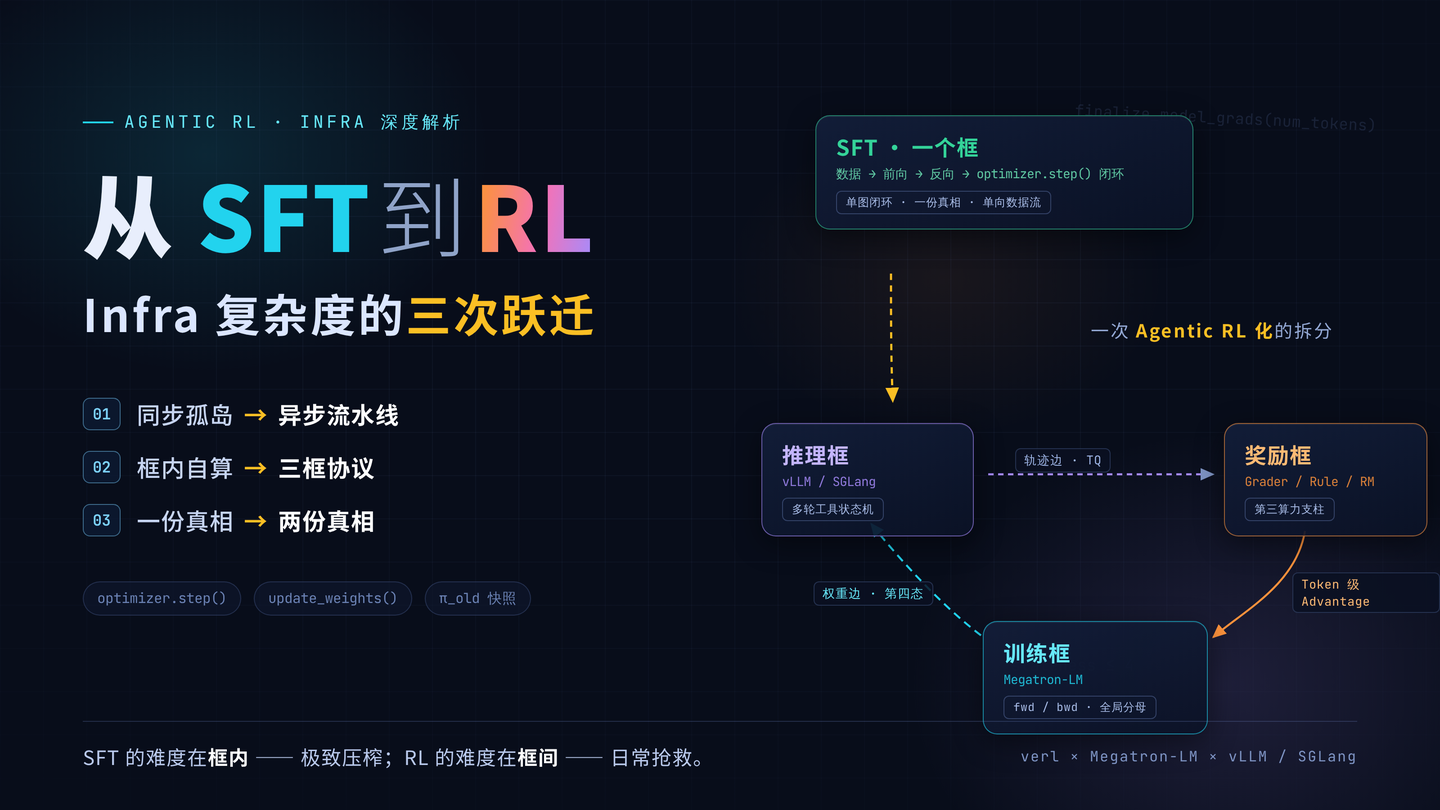

In [4]:
Image(filename='./Image/sft_rl_0.png')

- 作者： 去尘  https://zhuanlan.zhihu.com/p/2096722563741369409

目标读者：面向广大正在学习的及从事大模型前沿研究Agentic RL开发者们。
标本：verl + Megatron-LM core（bridge）+ vLLM/SGLang。

写在前面
写这篇文章是一次极其耗费心力的长途跋涉。发出了希望能和大家一起交流。

但受限作者个人的认知边界，书中内容难免存在疏漏、偏颇甚至错误之处。技术的探讨在于碰撞与纠错，若各位朋友在阅读时发现笔误、或者是作者思路狭窄未能理解核心奥义，非常欢迎指正交流。

# 0. TL;DR
如果把 Agentic RL 当成“带奖励信号的多轮 SFT”，大概率会在三个地方翻车。SFT 时代三个默认成立的假设，在 Agentic RL 里全部失效——而每一次失效，恰好对应一次 Infra 复杂度的跃迁：

- 假设一：数据是静态的。 SFT 从磁盘读固定分布；RL 的轨迹是策略自己在环境里探索出来的，分布随训练漂移，还要等 Sandbox / 工具的长尾响应。跃迁：同步孤岛 → 异步流水线（→ 第 5 章）。
- 假设二：Loss 当场可算。 SFT 的 CrossEntropy 是 Token 级、batch 内归一化就完事；RL 只有轨迹级奖励，要折算成 Token 级 Advantage，分母还是跨 PP/DP/CP 的全局协议。跃迁：框内自算 → 三框协议（→ 3.2.4节，第 4 章展开）。而且“算奖励”本身已不是附属步骤——grader compute 吃掉 RL 总算力的 12.7%（2026 年9月 15～20），奖励框升格为与 Rollout、Training 并列的第三根算力支柱（→ 4.2）。
- 假设三：权重一份真相。 SFT 的 optimizer.step() 原地回填、立即生效；RL 有两份权重真相——训练侧 buffer 和推理引擎显存——中间隔着一次昂贵的跨物理边界迁移。跃迁：一份真相 → 两份真相（→ 第 6 章）。

一句话版本：SFT 的难度在框内——同一张计算图里的极致压榨，崩了也是一个整齐的 NaN；Agentic RL 的难度在框间——三个框之间隔着长尾、异步和状态错位，日常不是优化，是抢救。

读完本文章能收获什么：

  - 根据适合自己的场景该选verl v1的trainer模式 sync / colocate_async / separate_async（→ 2.5节）；
  - grad_norm 无故冲到 1e4 时，知道先查分母协商，而不是怀疑梯度真爆了（→ 3.2.5节）；
  - 面对新任务时，能判断奖励框该用四类面孔中的哪一类、grader 什么时候必须从“共卡挤占”走向完全异步（→ 4.2、4.4）；
  - 权重同步出问题时，按五个可观测边界逐一定位（→ 第 6 章）；
  - staleness 爆表时，知道该调哪一层防线（→ 第 7 章）。
  
结构：1–2 章建框架，3–4 章看复用，5–7 章啃硬骨头。如果只关心权重同步，可直接跳到第 6 章；如果只想先建立全局直觉，1.3 节的对比表是全文最短的路线图。

# 先看图：SFT 与 RL 各长什么样
这一节讲什么：在讨论复杂度之前，先让读者对 SFT 和 RL 的组件拓扑建立直觉。后面的所有讨论都是在这两张图上做加减法。

##  SFT：只有一个框

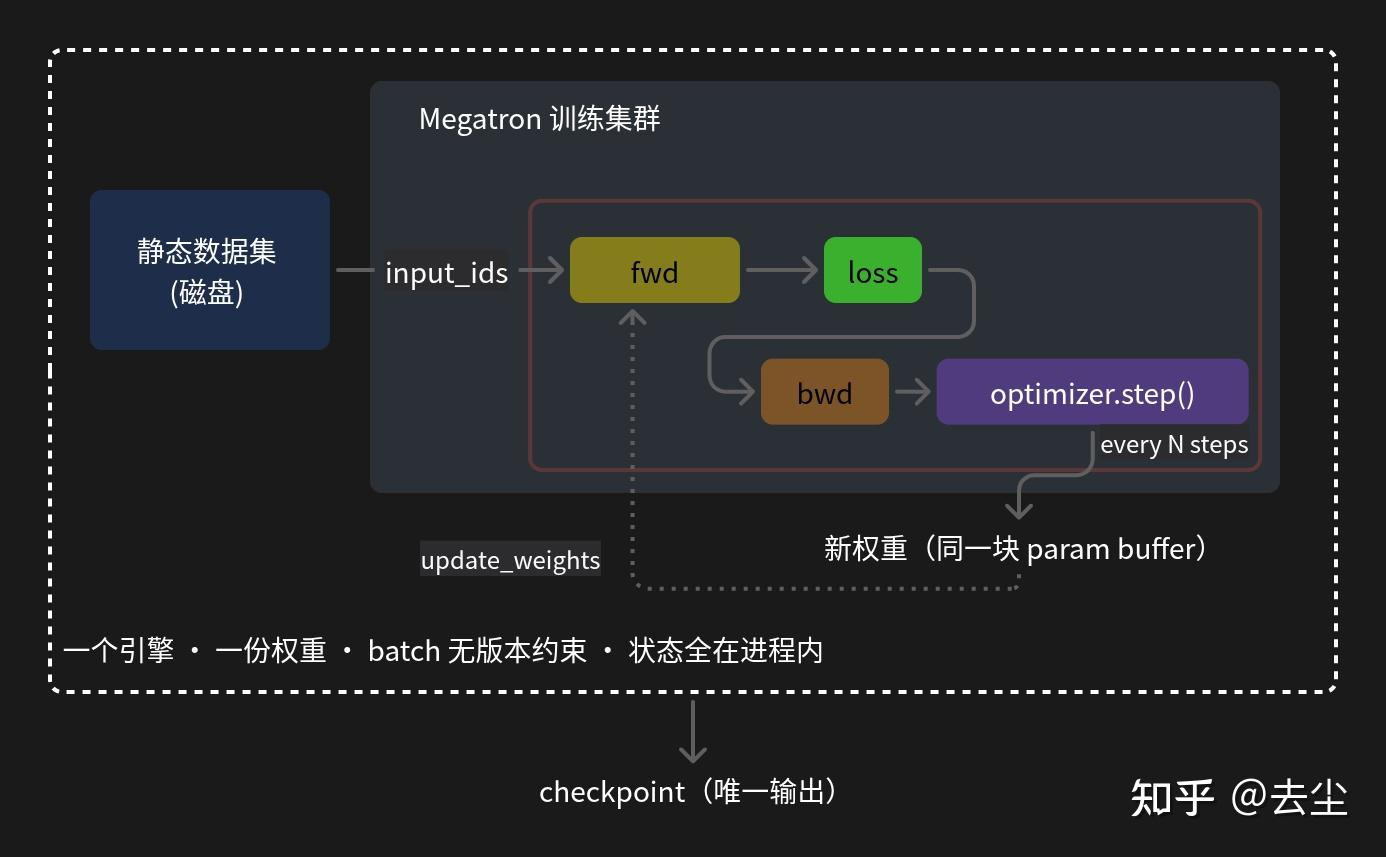

In [6]:
Image(filename='./Image/sft_rl_01.jpg')

一个孤岛：红框内完成了从数据输入到权重更新的绝对闭环。
一份真相：optimizer.step() 产生的新权重沿着虚线原地回填，立即生效，不存在推理端与训练端的不一致。
唯一的出口：除了周期性的 checkpoint 落盘，系统不向外部输出任何状态。

## RL：从“单图内的极致切分”，走向“双引擎间的协议对齐”
对比 SFT 的那座“孤岛”，很容易产生一种错觉：RL 的难在于“多了一个推理引擎”。这个判断只对了一半——多出来的不是一台机器，而是一套优化目标完全不同的执行体系。
SFT 的复杂度并不低。在长序列、万亿参数 MoE 的今天，SFT 同样要把 TP、PP、DP、EP、CP、SP 压到极限。但它的复杂度被严密收敛在同一个模型计算图、同一套通信域里：所有并行维度服务的是同一次前向/反向，所有集合通信发生在同一组 rank 之间，所有失败都可以归因到同一张图上的某一个算子。它的难，是物理切分与集合通信的难，但切分后的碎片仍然拼得回同一张图。Agentic RL 打破了这个收敛条件。它把系统拆成两套引擎：

但当跨入 Agentic RL，这个自洽的同构系统被彻底撕裂成了两套追求完全不同的异构巨兽：

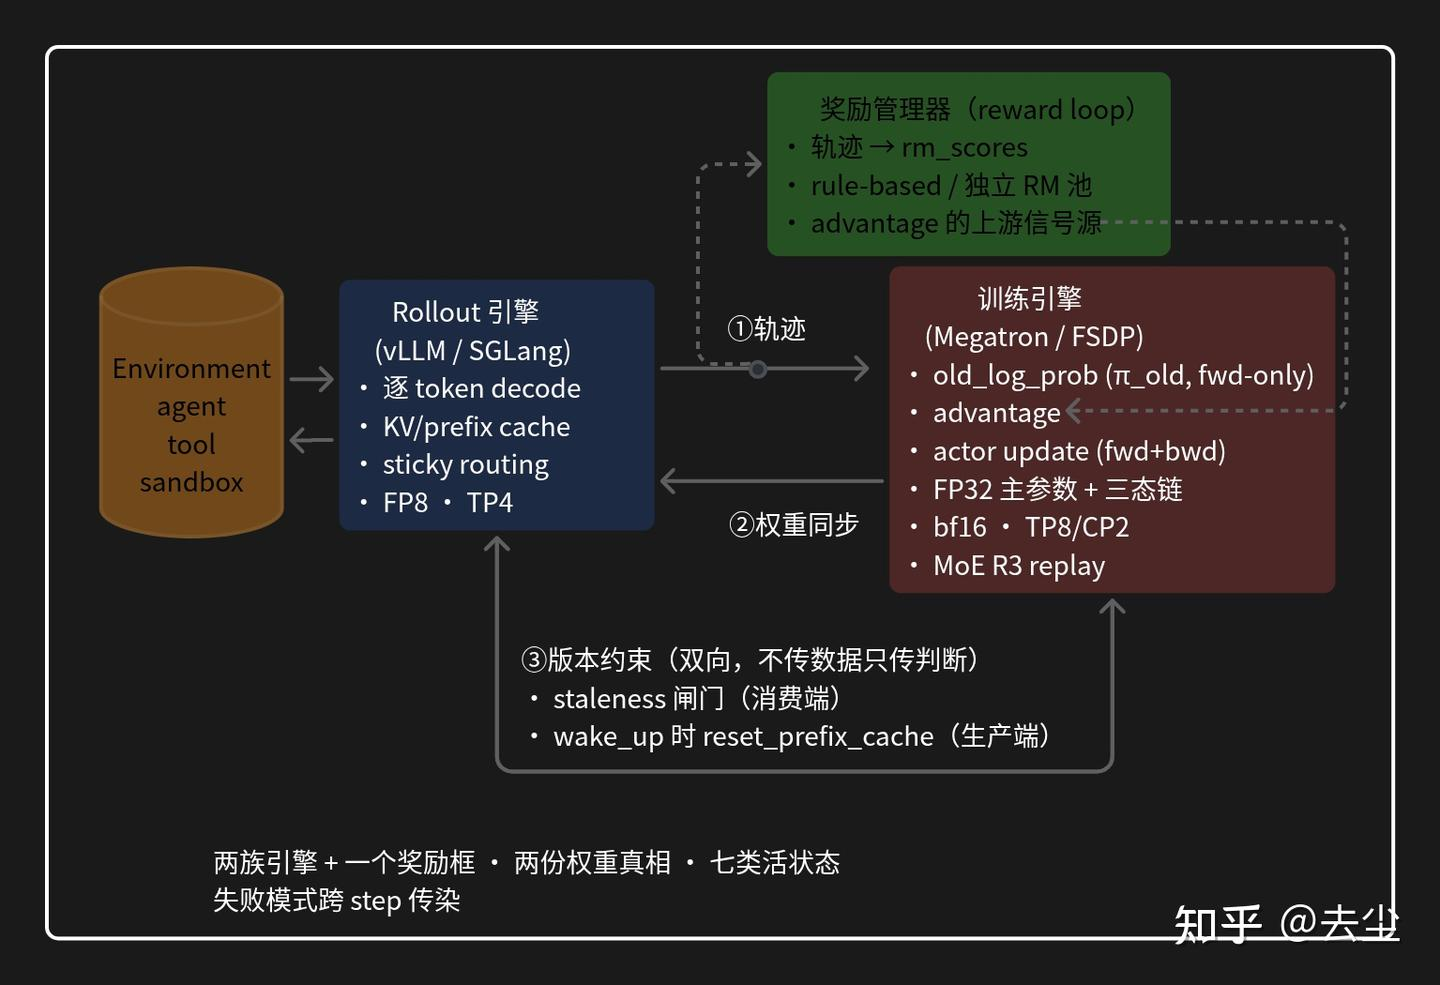

In [7]:
Image(filename='./Image/sft_rl_02.jpg')

- 推理引擎（vLLM/SGLang）：优化目标是请求延迟与吞吐。它围绕自回归解码做设计——PD 分离把 Prefill 和 Decode 拆到不同资源池，AF 分离把 Attention 和 FFN 拆到不同执行阶段，底层用 Cuda/Ascendc/Triton/TileLang/MegaKernel 把 decode 算子压到极致。它的并行维度（TP/EP）服务于“一个 batch 内的请求如何最快出 token”。
- 训练引擎（Megatron/FSDP）：优化目标是全局吞吐与显存效率。它用 PP/DP/EP/CP 把万亿参数摊到数千张卡上，用重计算、ZeRO、流水线气泡掩盖来换取单位时间内的 token 吞吐。它的并行维度服务于“一个 global batch 如何最快算完梯度”。

两者共享 PyTorch、CUDA、NCCL，但运行逻辑不在同一个抽象层：推理引擎的 TP 是为 decode 的 KV cache 布局服务的，训练引擎的 TP 是为 fwd/bwd 的梯度同步服务的；同一个 TP=8，在两侧切的是不同的张量维度。这就是“翻译边”的根源——不是数据格式转换，而是同一份权重在两套并行语义下的重新解释。

三条边，三种不同的“翻译”：
  - 轨迹边：推理引擎产出的是带环境长尾的、长度不一的轨迹；训练引擎要求的是形状对齐、可以立刻切 micro-batch 的 batch。这条边的难点不在传输，而在异步与同步的语义冲突——推理侧可以等一个 30 秒的沙盒返回，训练侧的 all-reduce 不能等。解法不是“把数据送过去”，而是“用队列把长尾隔离在训练 step 之外”（第 5、7 章）。
  - 权重边：训练侧的权重分布在 PP=16、EP=64 的拓扑上（以 671B/万亿 MoE 为例；实际配置随集群规模浮动），推理侧则需要按PD 分离重新布局。Attention/MLA 部分通常走DP（以分布 KV cache），MoE 部分走EP，具体数值随集群规模浮动——例如在超节点集群上，Prefill 阶段用EP=32，Decode 阶段用EP=320（每个 die 承载一个专家）；而在常规 H800 集群上，Decode 的 EP 可能是144量级。
  - 版本边：这条边没有数据，只有一条版本约束。推理引擎的 KV cache 是基于某个权重版本算出来的；权重一更新，所有 KV 立即变脏。版本边要传递的不是张量，而是“哪个版本的 KV 还能用、哪个版本必须作废”的协议。它的难在于没有显式的数据流可以观测——忘了 reset prefix cache，症状是“同一个 prompt 在新旧权重上给出两种结果”，极难复现（第 6.5 节）。
  
最后是状态问题。SFT 的计算图是无状态的：数据进来、梯度出去，中间不留下任何需要跨 step 维护的东西。RL 的推理引擎是有状态的：KV cache、在途请求、MoE 路由表、prefix cache、采样候选集、版本号、offload 状态——这些状态在 step 之间存活，并且任何一个状态与权重版本错位，都会污染后续轨迹。SFT 崩了，通常是一个整齐的 loss NaN 或梯度爆炸，可以定位到某一步；RL 崩了，可能是第 3 步的一条脏 KV 在第 17 步才表现为 loss 抖动，而那时权重已经更新了十几版。失败模式不再局限于单个 step，而是跨 step 累积

## 1.3 战场的转移：从“单图闭环”到“多态协同”
如果把前面两张图的差异浓缩成一张表，会发现：在 SFT 里，系统是一个绝对同构的闭环。算力全部用于压榨“同一个模型计算图”的吞吐——精调 PP/DP/SP 是为了减少流水线气泡，管理 Optimizer 三态链是为了省显存。虽然物理切分极其复杂，但所有计算都发生在同一套通信域内，数据流向是单向的。

但在 Agentic RL 里，这个自洽的闭环被撕裂了。算力不再只被消耗在“梯度计算”上，而是大量漏失在边界处：推理引擎的显存争抢、环境沙盒的长尾等待、跨网络的权重重排。RL Infra 的核心矛盾，从“如何压榨单一计算图”，变成了“如何让多套异构系统协同运转”。

这张表不仅是对比，更是本篇后续章节的作战地图：

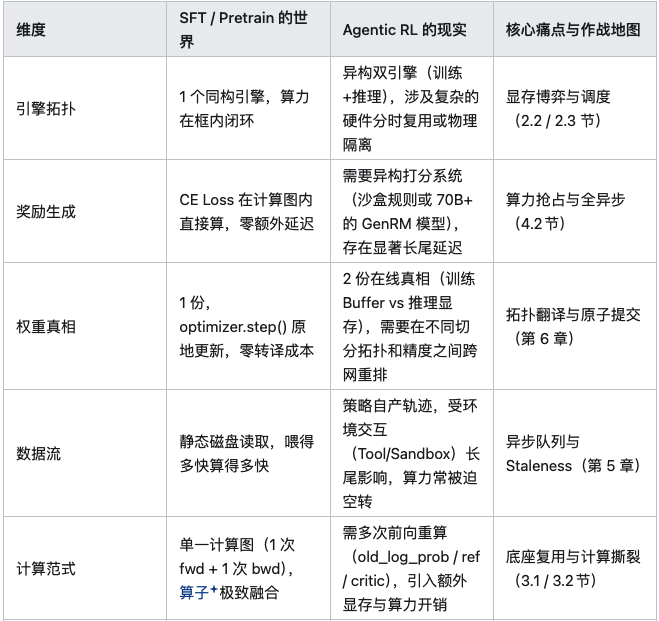

In [8]:
Image(filename='./Image/sft_rl_2.1.png')

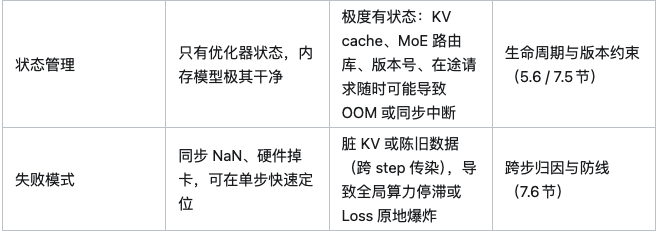

In [9]:
Image(filename='./Image/sft_rl_2.2.png')

SFT 的 Infra 任务是“把模型塞进显存，穷尽团队之力压榨单一计算图”；而 Agentic RL 的 Infra 任务，是在这套异构的分布式系统中，通过异步调度、零拷贝重排、严格的状态生命周期管理，去填平流水线气泡，把被跨网通信和状态错位浪费掉的算力抢救回来。

带着这份地图，我们正式进入硬核拆解。

# 先选框架：verl 的三种训练模式
这一节讲什么：在深入 RL 的复杂度之前，先交代 verl 支持的三档”rollout 与训练的关系”。后面所有的 off-policy、staleness、资源调度讨论都是在这三档下展开的——所以必须先有框架认知。

模式由 trainer.v1.trainer_mode 字符串决定（ppo_trainer.yaml 中预设了 "sync" / "colocate_async" / "separate_async" 三选一）。在代码层面，系统通过工厂函数 get_trainer_cls 查询 TRAINER_REGISTRY（定义于 trainer_base.py），动态实例化对应的 Trainer 类。

三种模式共用同一条数据流水线，差异只在四个自由度：谁在何时跑哪一段、权重怎么过去、staleness 多深、partial rollout 是否开。

本章结构导读：

  - 2.0 节：”从 YAML 到实例”的机制速览（一张全景图 + 三张速查表），完整的注册表与钩子推导收在【附录 A】；
  - 2.1–2.3 节：三种模式各给一张生命周期图 + 一段本质注解，实现细节指向代码行号；
  - 2.4 节：差异速查和钩子实现对照表；
  - 2.5 节：选型建议。
  
## 2.0 从 YAML 到实例：三种模式是怎么被”选中”的
  
trainer.v1.trainer_mode** 这个字符串背后藏着一条四段链路——YAML 声明 → 装饰器注册 → import 触发 → 运行时查找实例化。本节只给速览；完整推导见【附录 A】。**

### 2.0.1 全景链路

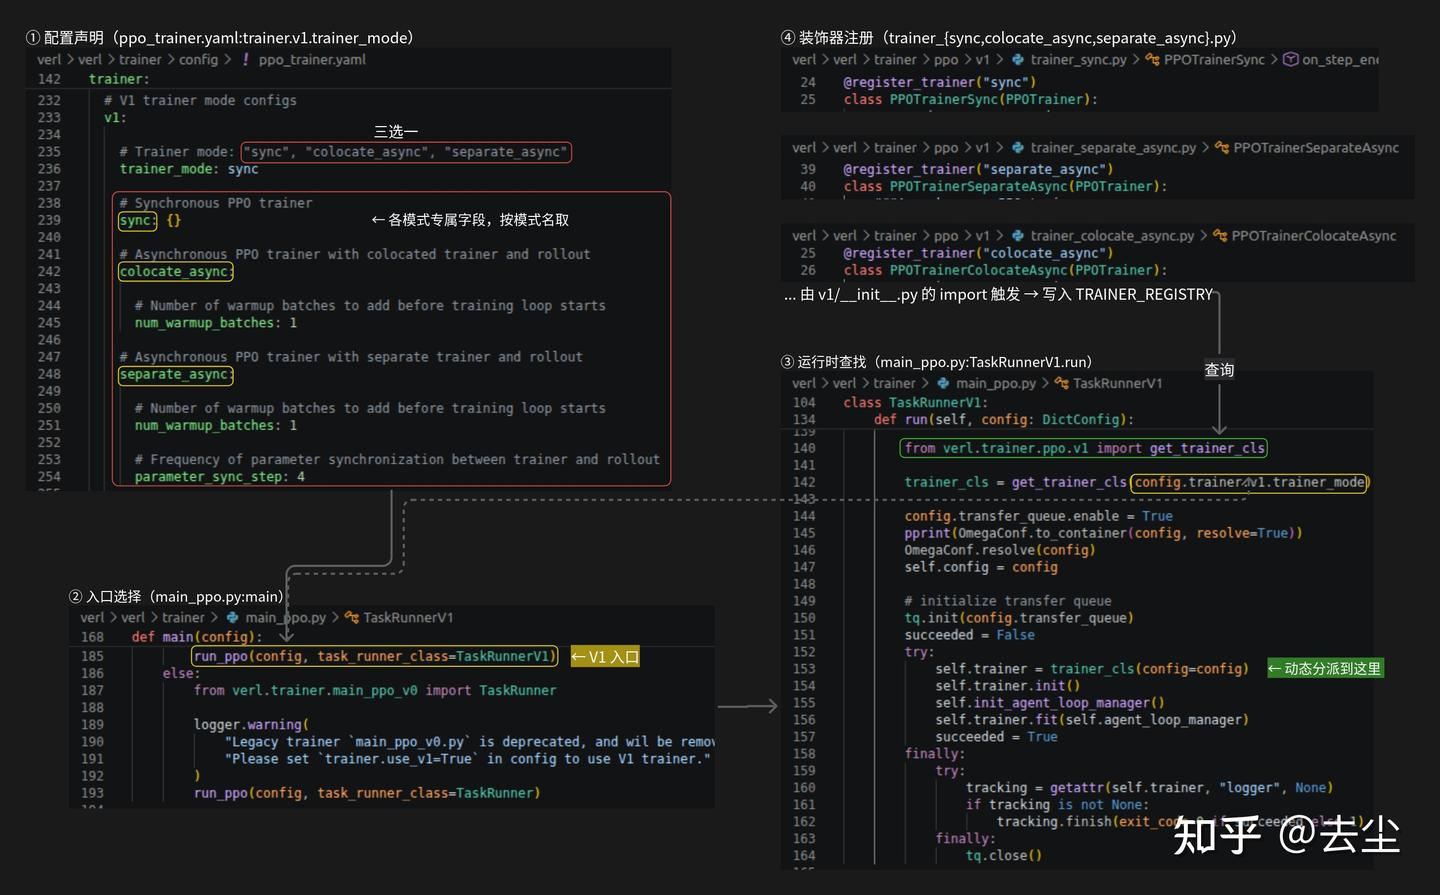

In [11]:
Image(filename='./Image/sft_rl_03.jpg')

读图要点：一套经典的控制反转（IoC）与注册表模式

这四段链路看似绕弯，实则是为了将“框架主干”与“具体实现”彻底解耦，这也是现代 Infra 框架最经典的设计模式：

  - ① YAML 声明式配置：用户只需在配置文件中声明字段（字符串），无需关心底层的类实例化逻辑。图中虚线明确显示了，这个字符串将成为后续查找的唯一键。
  - ② 入口版本路由：在 main_ppo.py 中通过开关完成 V0 到 V1 的平滑过渡，废弃老代码不影响历史包袱。
  - ③ 运行时动态解析：TaskRunnerV1.run 调用的工厂函数 get_trainer_cls 是解耦的关键，它利用 ① 中传入的字符串，去 TRAINER_REGISTRY 字典中做 O
 查找。
  - ④ 装饰器自动注册：三个子类文件通过 @register_trainer("xxx") 装饰器，利用 Python 包初始化（v1/init.py）的 import 副作用完成自注册。
  
架构收益：整条链路彻底消灭了恶心的大段 if/elif 硬编码分支。未来若要新增一种训练模式，只需新建一个类并打上装饰器，无需修改框架主干代码（符合对扩展开放、对修改关闭的开闭原则）。模式名的字符串，就是驱动底层实例化的唯一键。

### 2.0.2 注册：装饰器 + 注册表（两件套）
这套链路的底层实现极其克制，就是 trainer_base.py 末尾的两个变量与函数：

In [ ]:
# trainer_base.py # 完整实现在文件最尾端

# 1. 全局注册表：就是一个普通的字典
TRAINER_REGISTRY: dict[str, type[PPOTrainer]] = {}

# 2. 注册装饰器：利用 Python 的模块加载机制，将类自动写入字典
def register_trainer(name: str):
    def decorator(cls: type[PPOTrainer]):
        TRAINER_REGISTRY[name] = cls
        return cls
    return decorator

# 3. 获取函数：供入口处做 O(1) 查找
def get_trainer_cls(name: str) -> type[PPOTrainer]:
    return TRAINER_REGISTRY[name]

三个子类的”自报家门”分别落在各自文件头部：

In [ ]:
# trainer_sync.py
@register_trainer("sync")
class PPOTrainerSync(PPOTrainer): ...

# trainer_colocate_async.py
@register_trainer("colocate_async")
class PPOTrainerColocateAsync(PPOTrainer): ...

# trainer_separate_async.py
@register_trainer("separate_async")
class PPOTrainerSeparateAsync(PPOTrainer): ...

三个核心设计约束（详见附录 A）：

1. 严格匹配：装饰器中的字符串必须与 YAML 中的 trainer_mode 完全一致。
2. 幂等守卫：源码中包含了同名冲突检测（若同一个 key 绑定不同的类，会直接 raise ValueError），防止三方插件恶意覆盖内置模式。
3. 隐式触发：注册动作发生在 v1/init.py 被 import 的瞬间，而非 trainer_base.py 加载时。这是为了规避 Python 循环依赖的经典工程操作。

### 2.0.3 模板方法：9 个钩子速查表

PPOTrainer 的架构本质是一个典型的模板方法模式（Template Method Pattern）。基类 PPOTrainer 通过 init() → fit() → step() 确立了整个 RL 训练的主骨架，同时将 9 个关键生命周期节点暴露为 on_* 钩子。

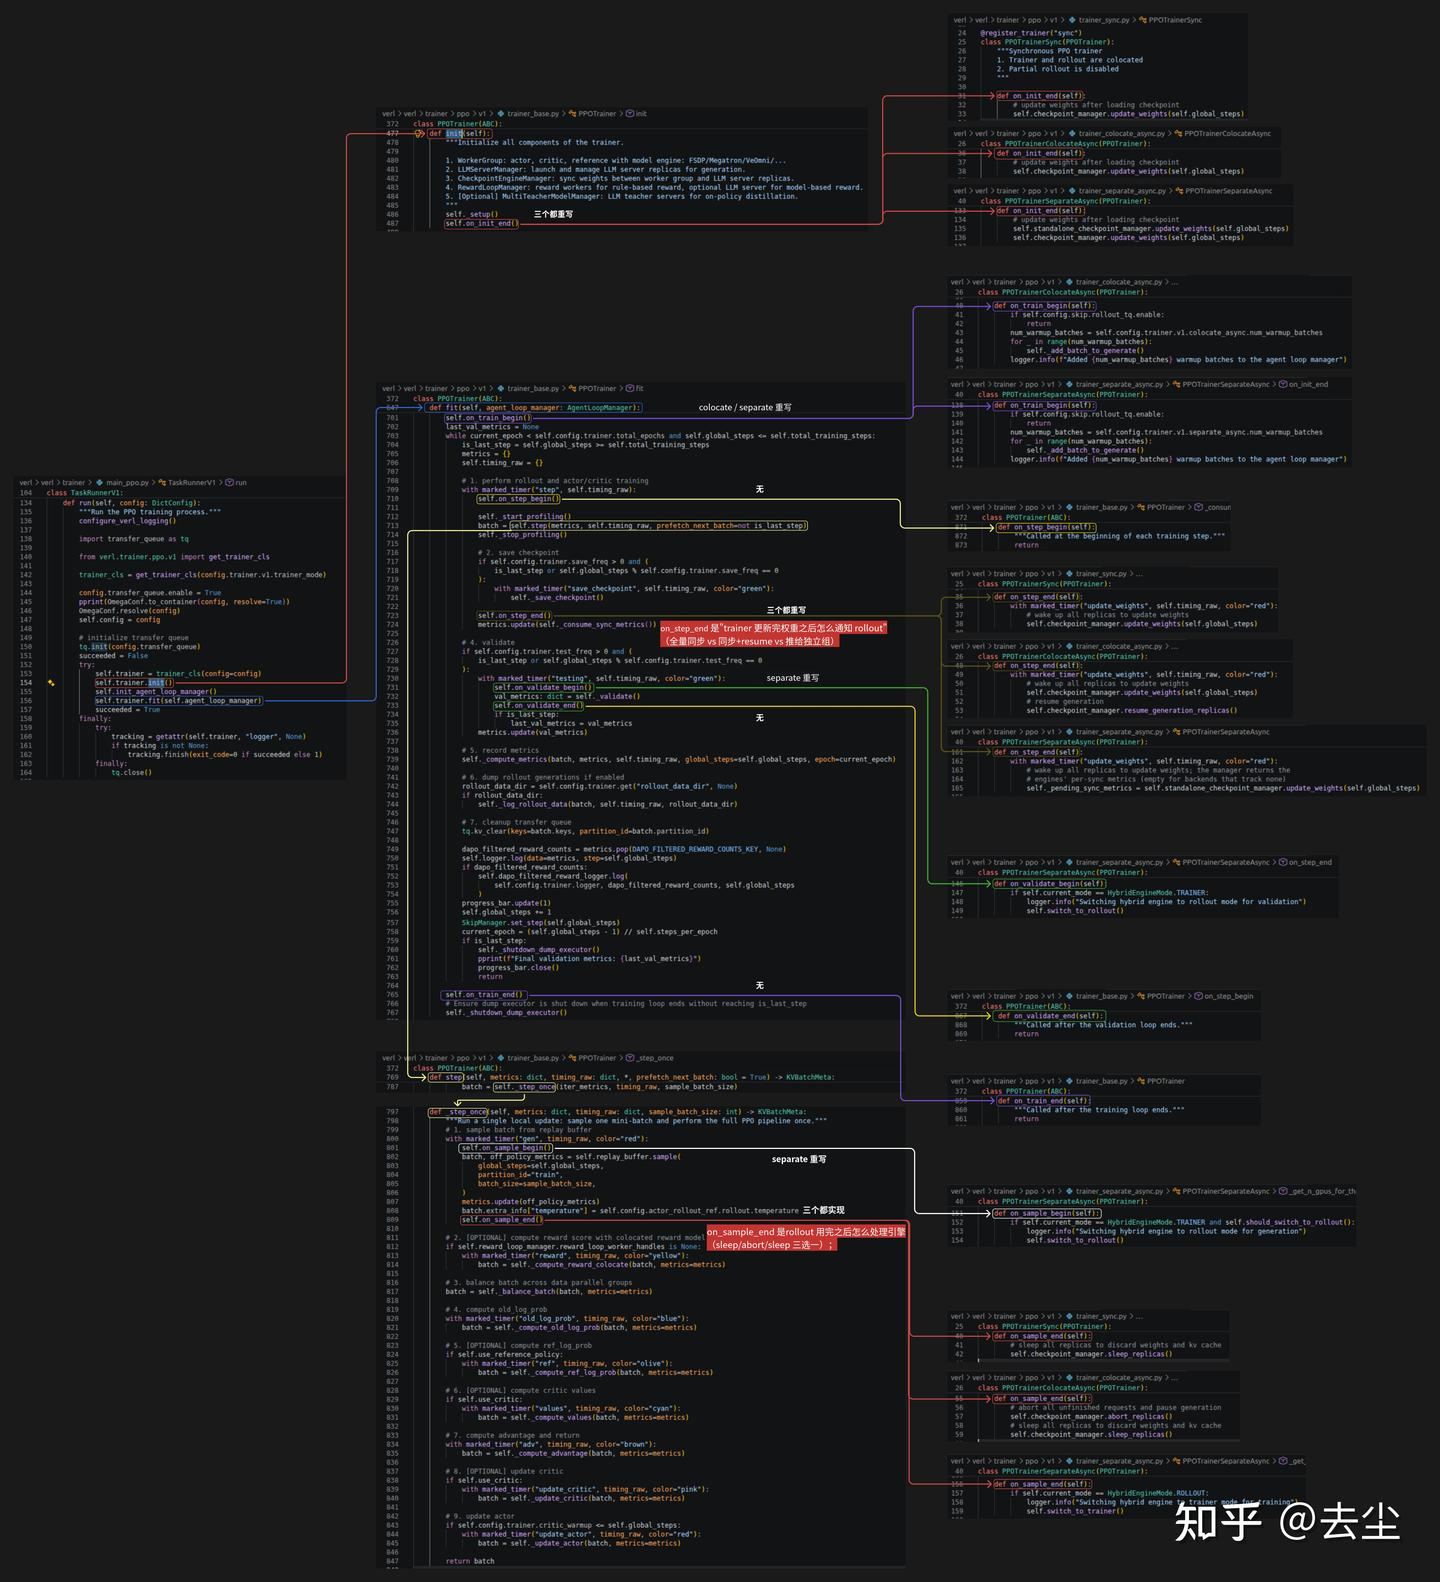

In [12]:
Image(filename='./Image/sft_rl_04.jpg')

#### 9 个钩子的重写矩阵：

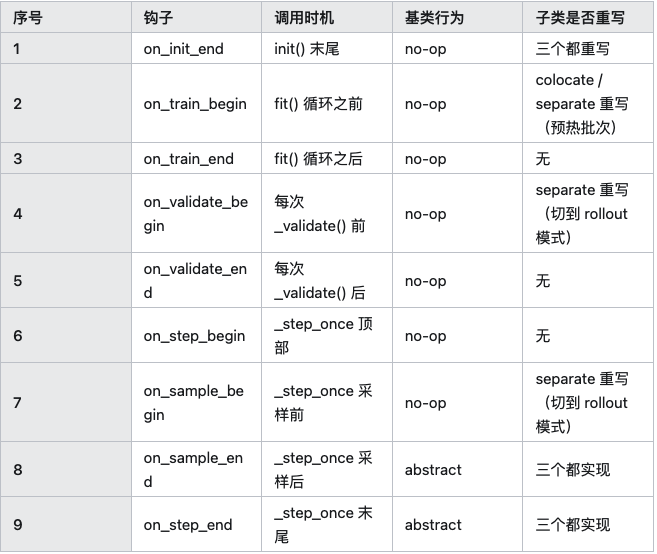

In [13]:
Image(filename='./Image/sft_rl_04.1.png')

设计认知：差异只在钩子，不在主干

1. 唯二的 @abstractmethod 切中命门：表格中唯二必须强制实现的是 on_step_end（更新完权重怎么通知引擎）与 on_sample_end（采完样怎么处理显存）。这恰好是 sync、colocate 和 separate 三种模式物理差异最大的两个点。
2. 通过重写实现配置分发（消灭 if-else）：三种模式的差异完全没有用恶心的 if self.trainer_mode == ... 写在基类里。基类只存一个字符串（trainer_base.py），具体行为全部由子类重写特定的钩子来表达。
3. 图的右半部分：可以清晰地看到 PPOTrainerSeparateAsync（最下方的类）因为需要动态借调算力，重写了最多的生命周期钩子（甚至包括 on_validate_begin 和 on_sample_begin 来做 switch_to_rollout 状态机切换）。而 PPOTrainerSync 只重写了最基础的三个。

注：至于基类里那几处“不得不写”的 if self.trainer_mode 分支（如 ReplayBuffer 分流），完整推导收在【附录 A.3】。

### 2.0.4 parameter_sync_step：改变“数据复用深度”的全局旋钮
self.parameter_sync_step = self.config.trainer.v1.get(self.trainer_mode, {}).get("parameter_sync_step", 1)（trainer_base.py）——这个字段决定了同一个全局 Batch 的数据，在推给推理端之前，会被训练侧反复“咀嚼”多少次。

在 PPOTrainer.step() 的核心骨架中，它被直接用作循环的边界条件



In [ ]:
# trainer_base.py:step（节选）
def step(self, metrics: dict, timing_raw: dict, *, prefetch_next_batch: bool = True) -> KVBatchMeta:
    train_batch_size = self.config.data.train_batch_size
    assert train_batch_size % self.parameter_sync_step == 0, (...)
    sample_batch_size = train_batch_size // self.parameter_sync_step

    if prefetch_next_batch:
        self._add_batch_to_generate()

    metrics_aggregator = MetricsAggregator()
    combined_keys: list = []
    # ★ 核心循环：一个 Global Step 内部会做 N 次 Local Update
    for trigger_idx in range(self.parameter_sync_step):
        self.local_trigger_step = trigger_idx
        batch = self._step_once(iter_metrics, timing_raw, sample_batch_size)
        ...

    metrics.update(metrics_aggregator.get_aggregated_metrics())
    return KVBatchMeta(partition_id=combined_partition_id, keys=combined_keys, tags=combined_tags)

一个 global step = parameter_sync_step次 local update 是本节三种模式的核心统一公式：

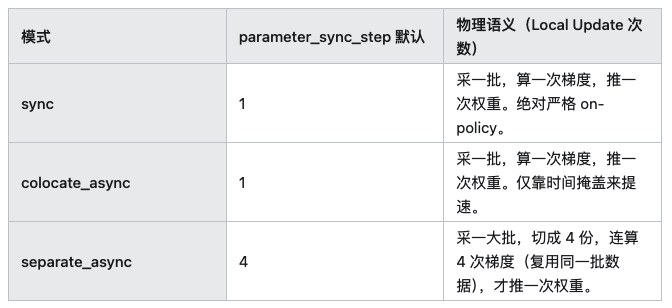

In [14]:
Image(filename='./Image/sft_rl_04.2.png')

这个数字不是装饰性的——它是 Infra 与算法妥协的艺术，直接引发了三重连锁反应：

1. Optimizer Horizon 的欺骗：因为一次 Global Step 里实际跑了 parameter_sync_step 次 optimizer.step()，所以在初始化时，必须欺骗 LR Scheduler，把总步数放大：optim_total_training_steps = total_training_steps * self.parameter_sync_step（trainer_base.py）。否则学习率会提前衰减到 0。
2. 引出 Decoupled PPO 与 
快照：在 separate_async 的这 4 次连续更新中，策略参数 
发生了 4 次改变，但数据都是由同一个老版本 
生成的。为了训练稳定，不能每次都拿最新的 
去当分母。local_trigger_step（0~3）这个索引，被 separate_async 用来做底层 CPU 权重快照（详见 2.3 节末尾的 _compute_old_log_prob 重写代码）。
3. 划定了 staleness 的物理上界：推理端必须等这 4 次本地更新全部做完，才能拿到新权重。这就注定了一批轨迹从出生到被消费，极有可能横跨了 4 个版本（详见 7.2 的 staleness 闸门）。

### 2.0.5 延伸阅读：基类里那些“不得已”的妥协
虽然verl极力通过钩子重写来消灭硬编码，但在基类深处，依然有四处不得不写 if self.trainer_mode == ... 的妥协点。如果在调参时遇到困惑，大概率是踩到了这些底层设计：

  - 改了配置没生效？ 看看 v1/init.py 是如何利用 import 的副作用触发装饰器注册的（【附录 A.1】）。
  - separate_async 报错？ 它在 init 里写死了 3 条关于切分、后端和奖励池化的物理约束（【附录 A.2】）。
  - 基类被污染？ 为了处理 TQ 持久化、Checkpoint 恢复和 Dataloader 精度，基类保留了四类被动分支（【附录 A.3】）。
  - Sampler 表现异常？ 去查 ReplayBuffer 与 Async 版本分水岭（【附录 A.4】与 2.4）。

## 2.1 sync：共享 GPU · 严格串行 · on-policy
本质：三个钩子把共享显存切成两半——采样时 vLLM 占据，训练时 Megatron 占据，严格互斥。没有重叠，staleness=0，算法最干净、吞吐最低。

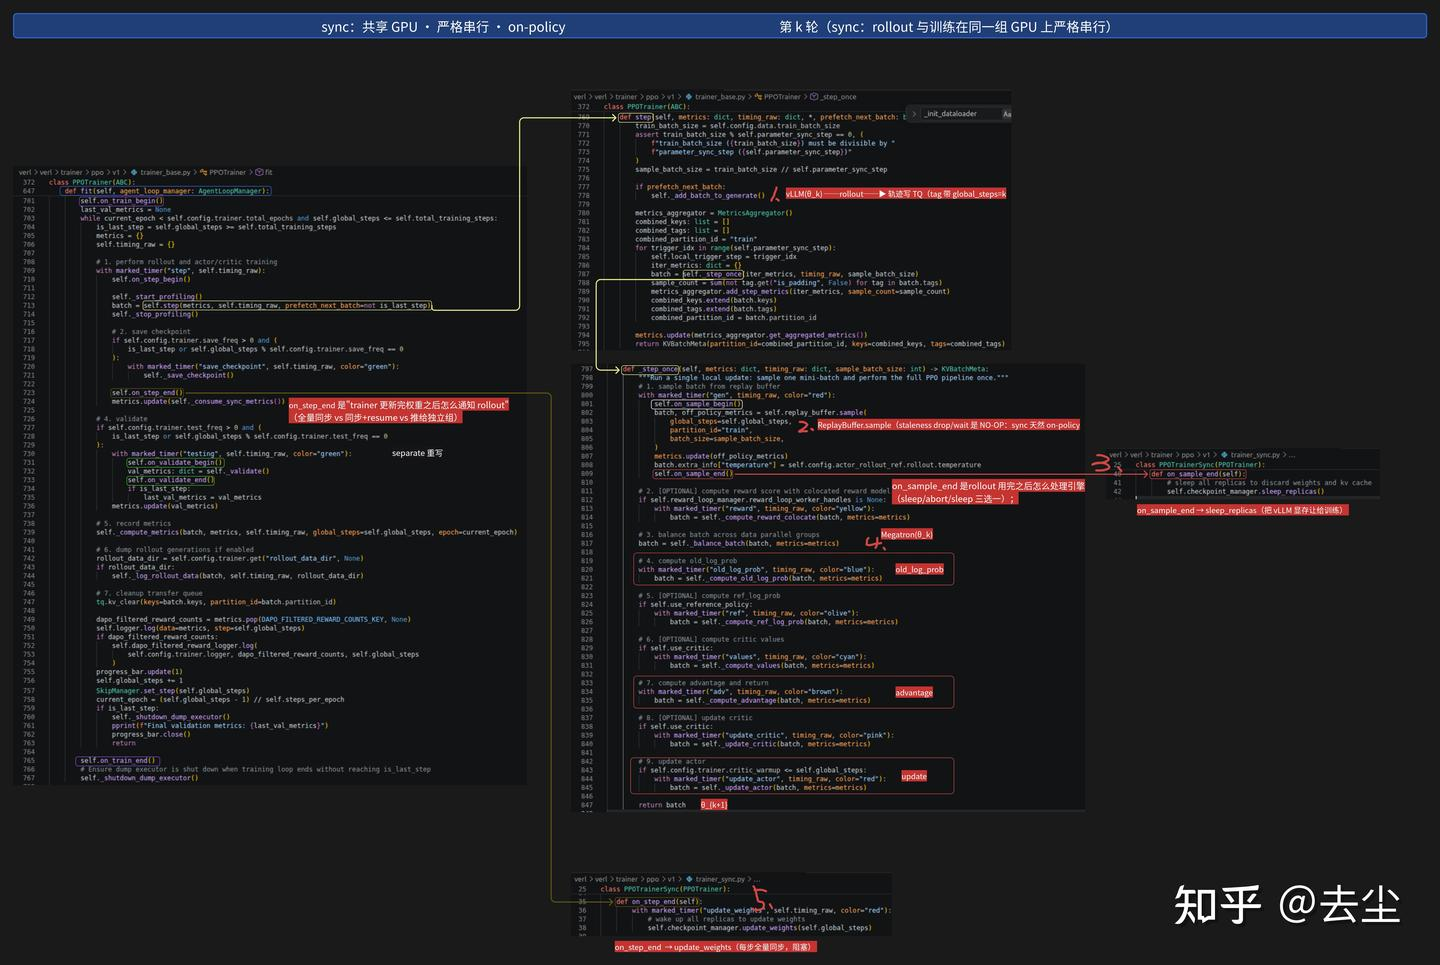

In [15]:
Image(filename='./Image/sft_rl_05.jpg')

读图要点（请结合上图）：

1. 极简的 18 行代码：看图的右侧，trainer_sync.py 只重写了三个钩子，没有任何复杂的 abort 或 drain 逻辑，极度干净。
2. 严格执行的串行主循环：看图的左侧，在 fit() -> _step_once() 的骨架里，gen（采样）、old_log_prob、actor update 依次发生，中间没有任何并行掩盖。前一个阶段没跑完，下一个阶段绝不可能开始。
3. 显存的时间分片：右侧代码中的 on_sample_end 会调用 sleep_replicas() 把 vLLM 的显存完全释放；紧接着 on_step_end 会调用 update_weights() 唤醒 vLLM 并推入新权重。
4. 原生的 on-policy：注意图中右侧的 on_step_end，它调用的是基类本地的 checkpoint_manager.update_weights。因为是同一组进程/GPU，更新完立刻进入下一轮采样，天然保证了绝对的新鲜度（staleness=0），完全不需要复杂的 ReplayBuffer 驱逐和 IS/RS 校正。

代价：看左侧的代码执行流，vLLM 在训练时处于休眠，Megatron 在采样时空转，两套引擎交替闲置，硬件的利用率不到一半。

适用场景：

  - 什么时候强烈推荐用？
    - 算法调试与排雷期：当在 GRPO/PPO 上测试一种新的 Loss 函数或 Advantage 估计器时，必须用 sync。因为它是绝对 on-policy 的，如果此时 loss 不降或崩溃，可以 100% 确定是算法写错了，而不用去怀疑异步带来的陈旧数据问题。
    - 轻量级环境 / 短序列训练：如果单步 rollout 很快（比如没接任何工具，仅仅是生成 512 个 token），串行带来的空转时间可以接受。
  - 什么时候绝对不能用？
    - 长尾 Agent 环境（如 Sandbox / 编译 / 工具调用）：在 Agentic RL 中，一次环境交互可能耗时 30 秒甚至几分钟。如果用 sync，训练集群必须干等所有环境跑完才能更新，此时 GPU 利用率会跌到 10% 以下，算力成本直接爆炸。
    - 大规模集群 / 千亿参数模型：在几百张卡上跑 sync，训练和推理互相让位的空转成本是无法接受的，必须上异步（colocate_async 或 separate_async）。
    
## 2.2 colocate_async：共享 GPU · 采样与训练重叠 · 每批最新权重
本质：同一组物理 GPU 上的“显存分时复用”。通过极其苛刻的 sleep（休眠）与 wake（唤醒）交接，实现了每一批权重都是最新（staleness ≤ 1），并在交接的缝隙中榨取重叠时间。

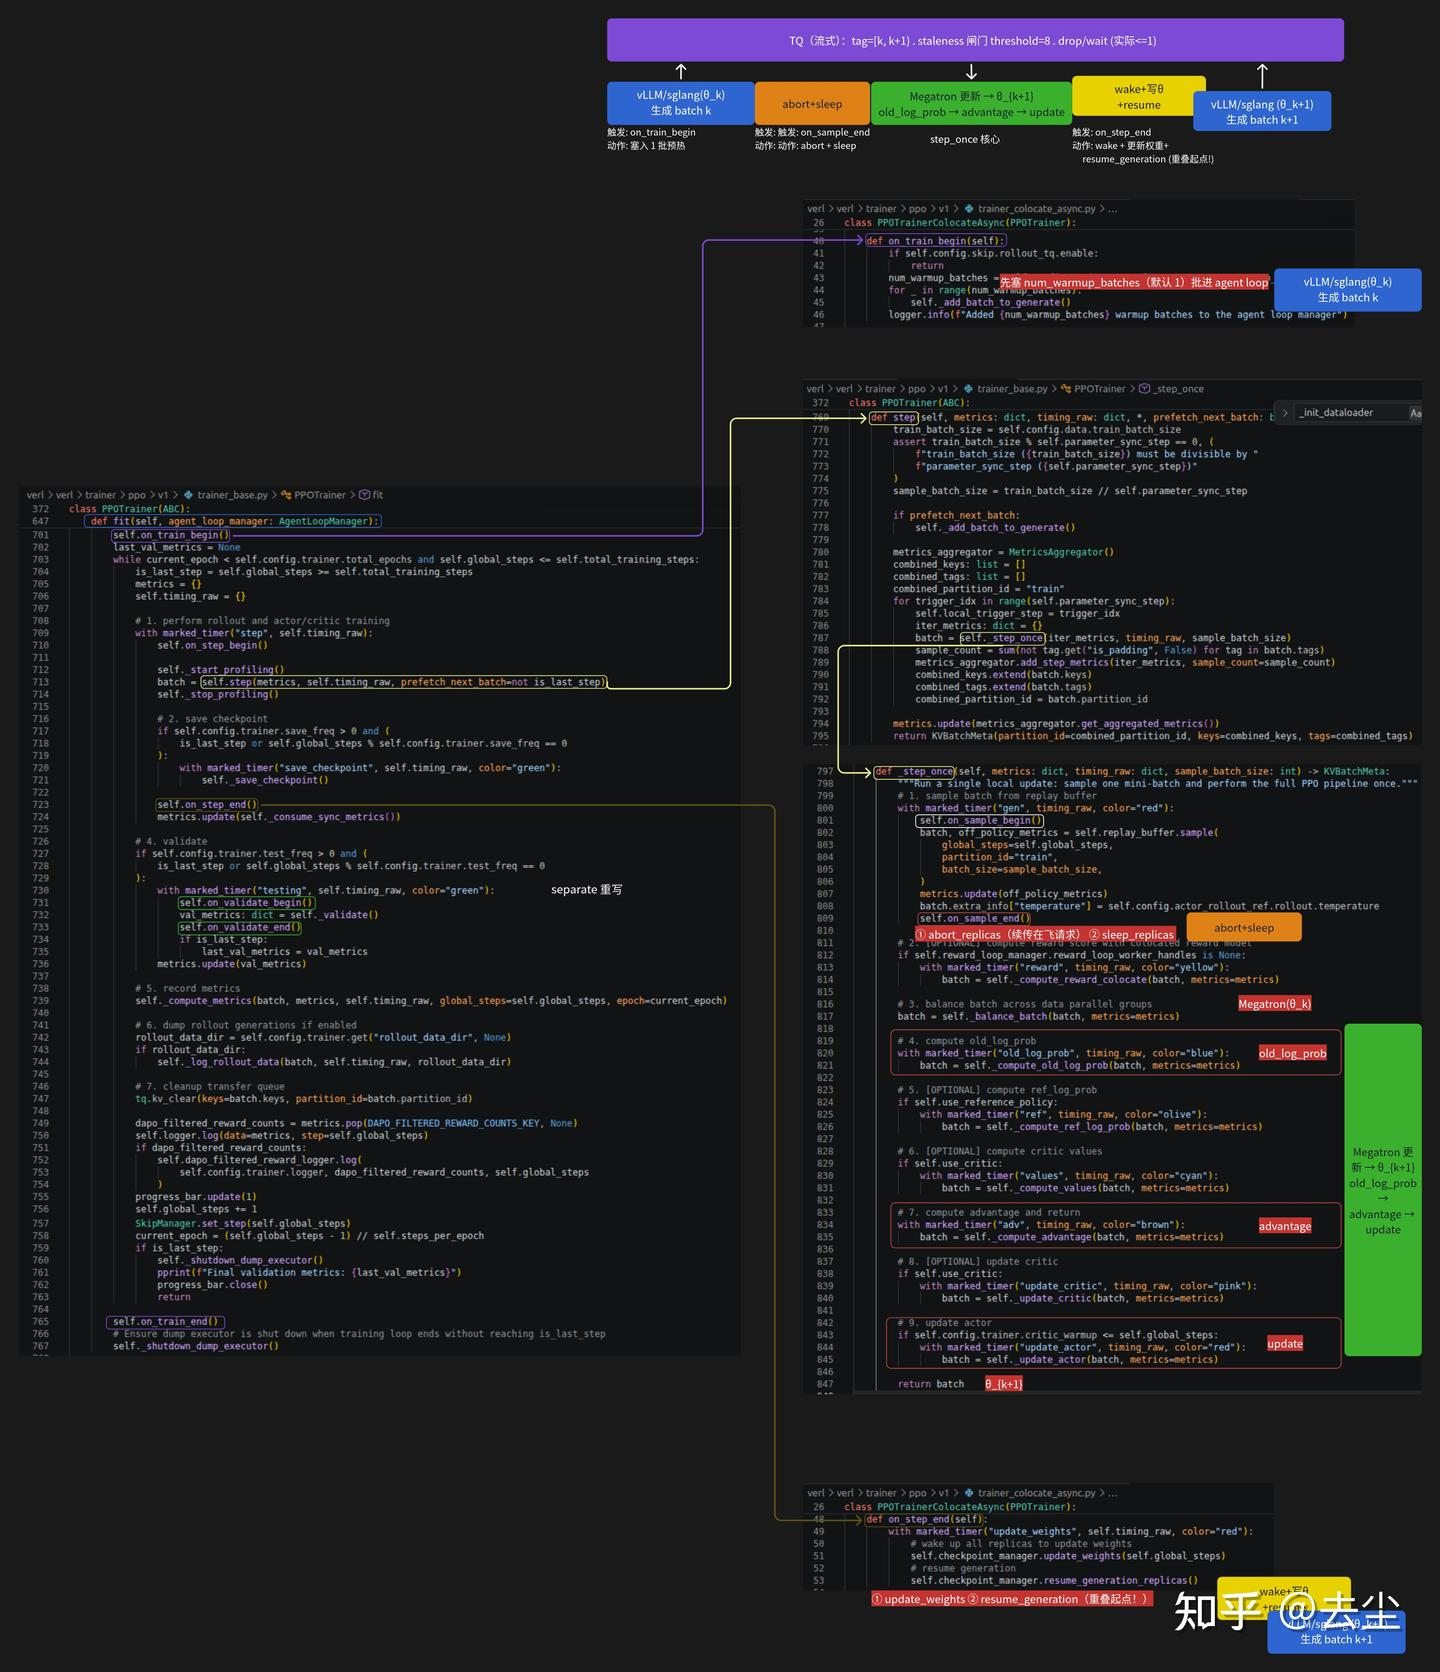

In [16]:
Image(filename='./Image/sft_rl_06.jpg')

读图要点（顺着时间轴与颜色看）：

全景图解析（顺着颜色看）：

1. 蓝块起步（起跑）： 看图的左上角。在训练开始前，on_train_begin 先塞入了预热批次，让 vLLM 先飞起来，把生成的轨迹源源不断写入顶部的紫色 TQ 队列。
2. 橙块交接（让出显存）： 当 _step_once 从 TQ 拉到足够数据后，触发中间橙块的 on_sample_end。代码极其粗暴地 abort（中断在飞请求）并 sleep（清空显存），逼着 vLLM 让出 GPU，交给 Megatron 开始九步训练。
3. 绿块发力（训练独占）： vLLM 休眠期间，Megatron 疯狂跑 old_log_prob -> advantage -> update，GPU 利用率拉满，不受任何推理干扰。
4. 黄块接力（重叠起点！）： 九步计算完成后，触发右下角黄块的 on_step_end。新权重被推入，并立刻调用 resume_generation 唤醒 vLLM。 看时间轴的最右侧：就在这一瞬间，vLLM 带着 θ_{k+1} 重新起飞（右侧蓝块），而 Trainer 主循环还在后台跑 metrics.update。这段重合的缝隙，就是它比 sync 快的地方。

staleness 的来源（顶部紫条）： 因为橙块里的 abort 操作，半截轨迹会被强制中断。它们会在下一轮带着旧版本的烙印继续生成（Partial Rollout）。所以标签是 [k, k+1)，staleness 严格锁死在 ≤ 1。

## 2.3 separate_async：独立 GPU · 真并行 · 异步流水线
本质：用硬件换一致性的自由度——两组独立的 GPU 集群各自常驻，彻底告别了 colocate_async 里昂贵且危险的 sleep/wake 显存体操。代价是引入了受控的陈旧数据（staleness），并需要一套精密的“自救”机制。

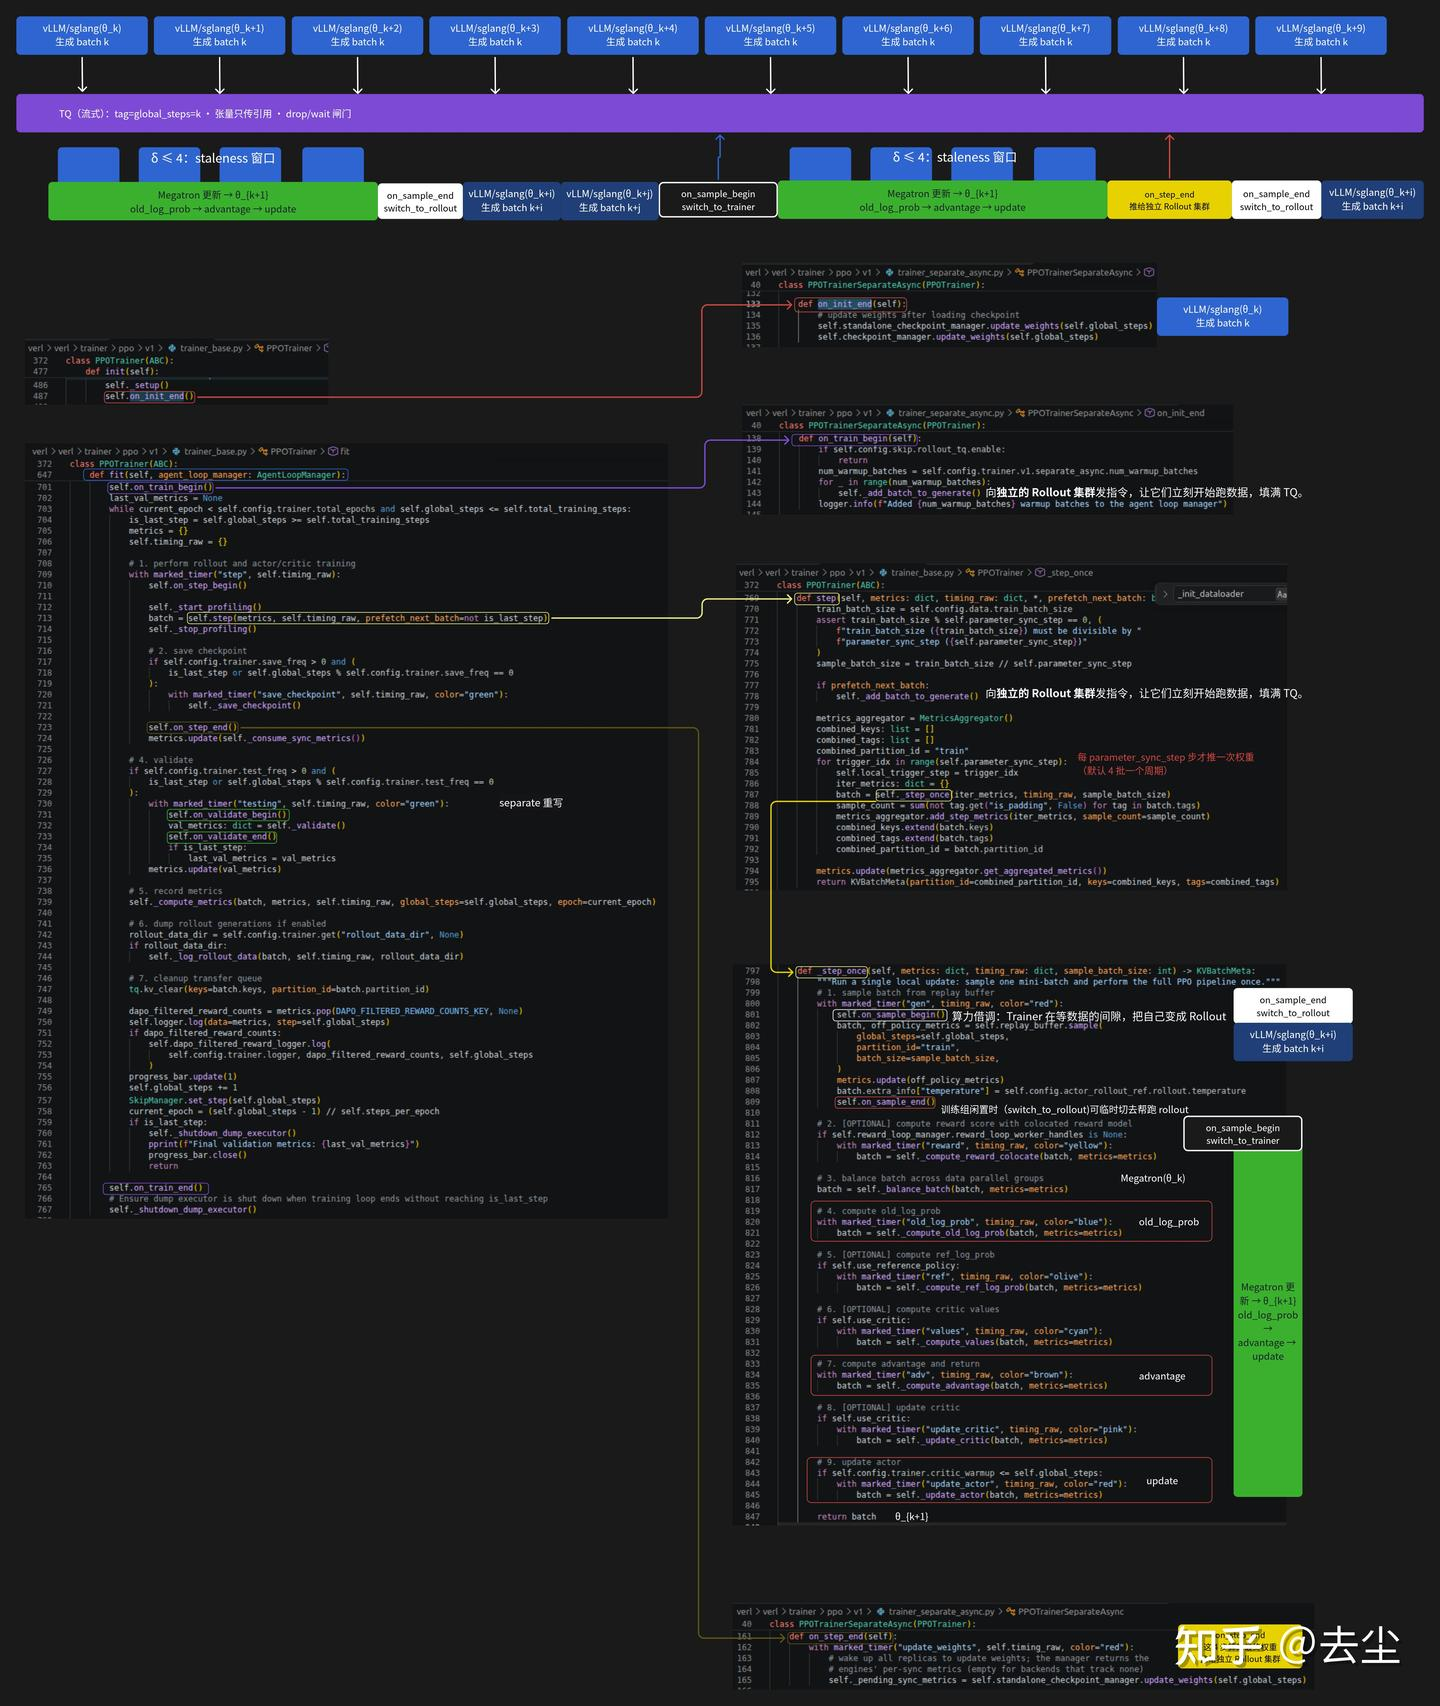

In [17]:
Image(filename='./Image/sft_rl_07.jpg')

### 1. 核心认知：系统里其实藏着“两个 Rollout 引擎”
看代码时会被 checkpoint_manager 和 standalone_checkpoint_manager 搞晕。实际上，在 separate_async 的初始化代码 _setup 中，创建了两套完全独立的推理资源：

1. 独立集群（Standalone Rollout）：真正的大部队。部署在专属的 GPU 池上，由 standalone_server_manager 管理。它们常驻、不 sleep，像永动机一样用旧权重生成数据写入 TQ。
2. 共卡集群（Co-located Rollout）：Trainer 自带的“备胎”。就在 Trainer 自己的显存里（平时休眠），由基础的 checkpoint_manager 管理。它不是用来跑主线的，而是专门用来“救急”的。

### 2. 各自为战的权重更新链路（看图中的黄块与灰块）
因为有“两个 Rollout”，所以权重同步也分成了两条完全不同的链路：

- 跨网推流（主循环）：看时间轴黄色块 on_step_end，Trainer 算完 4 步（parameter_sync_step）后，调用 self.standalone_checkpoint_manager.update_weights。这是把新权重 θk+1跨网络推给独立集群。此时训练完全不停（blocking=False）。
- 原地推流（借调时）：看灰色块 switch_to_rollout，当 Trainer 决定客串时，调用 self.checkpoint_manager.update_weights。这是把当前参数原地（同卡）塞给备胎引擎，毫秒级完成。

### 3. 混合架构（HybridEngineMode）：饥饿急救的精髓
为什么需要借调？因为独立集群偶尔会“供不上货”（长尾请求卡死），这时 TQ 里没数据了，Trainer 的 GPU 面临空转。 注意看图中穿插的灰色-蓝色-灰色块，这就是 switch_to_rollout 与 switch_to_trainer 的魔法：

1. 发现饥饿：在 on_sample_begin 钩子中，Trainer 检查 TQ，发现没货了（或者 should_switch_to_rollout() 返回 True）。
2. 原地变身：Trainer 立刻执行 switch_to_rollout。它暂停训练，把刚才算出来的最新权重灌给身边的备胎 vLLM，自己充当 Rollout 引擎，疯狂跑出两批（图中蓝色块 batch k+1）最鲜活的数据塞进 TQ。
3. 吃饱复活：在 on_sample_end 钩子中，Trainer 发现数据够了，执行 switch_to_trainer。它把备胎重新休眠，把当前 GPU 切回 Trainer 模式，立刻吃掉刚才自己打出来的新鲜数据（绿块），继续算梯度。

### 4. 为什么会有 δ≤4的 Staleness？
看图中的 δ≤4 窗口。无论是独立集群打的数据，还是 Trainer 客串打的数据，它们最终都汇聚在 TQ 队列里。因为独立集群每 4 步才能收到一次新权重（parameter_sync_step=4），这就注定了一条轨迹从出生到被 Trainer 消费，中间最多可能跨越 4 个版本（θk−4 到 θk）。

这也是为什么 separate_async 必须开启 IS/RS 校正（7）——用数学手段去抹平这 4 个版本带来的分布偏移。

### 代码深潜：为什么必须做“CPU 权重快照”？
在 2.0.4 节我们提到，separate_async 默认 parameter_sync_step=4。这意味着，它会用同一批轨迹数据连续算 4 次梯度。在这个过程中，πθ 的参数已经悄悄更新了 4 次，但生成这批数据的策略 πold却永远停留在了第 0 步。

为了保证 PPO 算法的 ratio 分母（πold）在这 4 次更新中绝对稳定，PPOTrainerSeparateAsync 不得不重写 _compute_old_log_prob，上演一场极其昂贵的“显存与 CPU 之间的往返体操”：

In [ ]:
# trainer_separate_async.py:_compute_old_log_prob（逐字）
def _compute_old_log_prob(self, batch: KVBatchMeta, metrics: dict) -> KVBatchMeta:
    # ... bypass_mode 检查省略 ...
    
    # 【第 0 次局部更新】(local_trigger_step == 0)
    if self.local_trigger_step == 0:
        # 当前权重就是 π_old，直接存进 CPU 备份
        self.actor_rollout_wg.save_model_to_cpu(0)
        return super()._compute_old_log_prob(batch, metrics)
        
    # 【第 1~3 次局部更新】(local_trigger_step >= 1)
    else:
        # 1. 把当前最新的权重暂存到 CPU
        self.actor_rollout_wg.save_model_to_cpu(self.local_trigger_step)
        
        # 2. 把第 0 步存进 CPU 的 π_old 恢复回 GPU
        self.actor_rollout_wg.restore_model_from_cpu(0)
        
        # 3. 用旧的 π_old 计算 log_prob
        result = super()._compute_old_log_prob(batch, metrics)
        
        # 4. 算完之后，把当前最新的权重恢复回 GPU，继续做后面的 Actor Update
        self.actor_rollout_wg.restore_model_from_cpu(self.local_trigger_step)
        self.actor_rollout_wg.clear_cpu_model(self.local_trigger_step)
        return result

这就是“用硬件换吞吐”的底层代价： 在 separate_async 走这 4 步的过程中，GPU 显存和 CPU 内存之间会发生极其频繁的权重互换。如果不做这个 CPU 快照，模型要么因为分母漂移而崩溃，要么因为把 4 个版本的权重全驻留在 GPU 上而直接 OOM。这是异步流水线在算法正确性上留下的“时空间隙”。

## 2.4 差异速查：三张面孔的“物理动作”对比
三种模式没有绝对的优劣，只有对物理资源的妥协与榨取。透过这张表，可以清晰地看到它们在四个核心自由度上的分道扬镳：



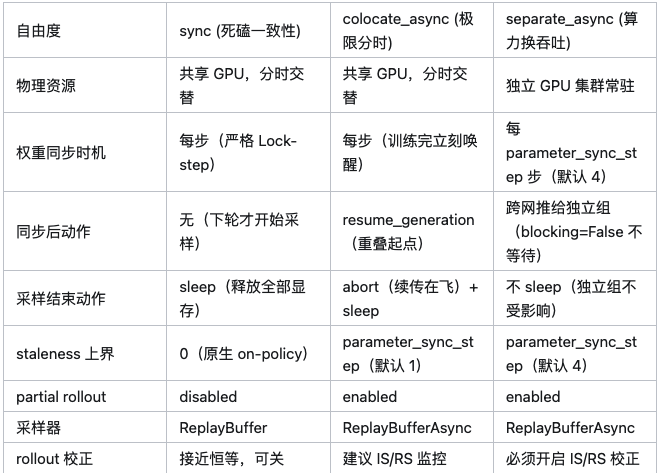

In [19]:
Image(filename='./Image/sft_rl_07.1.png')

staleness 口径说明： 本系列统一说”≤ parameter_sync_step“，因为上界由权重同步周期直接决定；默认值 colocate 是 1、separate 是 4。必须区分”可达（实际可能触发的最大延迟）”和”≤（理论安全边界）”。

## 2.5 怎么选：从业务痛点出发
不要被“默认推荐”或“大规模”这种模糊的词汇误导，选型的本质取决于业务场景在哪个环节最痛：

- 选 sync：处于算法排雷期，或环境交互极快。
  - 适用：刚开始调 GRPO/PPO 的 loss 公式、Reward 函数时；或者任务没有工具调用，纯文本生成一步只要几秒钟。
  - 避坑：如果任务要调沙盒编译代码，或者多轮对话经常卡死 30 秒以上，绝对不要用 sync。因为只要有一个长尾请求没结束，整个庞大的训练集群就得干等着。
- 选 colocate_async：只有一套 GPU，且希望掩盖冷启动空转。
  - 适用：中小团队，买不起两套独立集群。这是本仓的默认推荐，用极端的“显存分时复用”换取了比 sync 高得多的 MFU。
  - 注意：需要忍受每轮极其苛刻的 abort + sleep + wake 显存体操。
- 选 separate_async：Agent 任务极重（重度依赖 Sandbox / 工具），且有钱买独立推理集群。
  - 适用：大规模生产环境的终极形态。即便 Rollout 集群拼命跑，Trainer 也会随时面临数据饥饿。它甚至允许 Trainer 在没数据时，自己临时变成 Rollout 去“救急打工”。
  - 注意：它的 staleness 管理难度最高，必须配合 7 的 IS/RS 校正机制作为保险丝。

# RL 复用的 SFT 底座：三条接口
这一节讲什么：把 1.1 章中那个“框内”的结构，用 megatron-core 源码落实成三条 RL 会直接调用的接口。目的不是介绍 Megatron 内部实现，而是给第 4 章一个精确的对照系——说清楚 RL 到底复用了哪三样东西、在什么场景下被调用、以及 RL 最终在哪里“切出了第四态”。

## 接口 A：get_forward_backward_func —— 工厂三选一与前向/反向开关
这一节讲什么：RL 的“多次前向 + 多次反向”并非另起炉灶，而是全盘复用了 Megatron 的调度器。本节通过源码（基线：megatron-core commit 1d462bd，verl 镜像锁定版本）厘清两个层面的映射：调度器分支（由拓扑决定，RL 从不改变）与 RL 各计算环节（由 forward_only 一个布尔值区分）。

### 工厂三选一
get_forward_backward_func()（schedules.py）是一个工厂函数，根据 PP/VPP 拓扑返回三种实现中的其中一个：

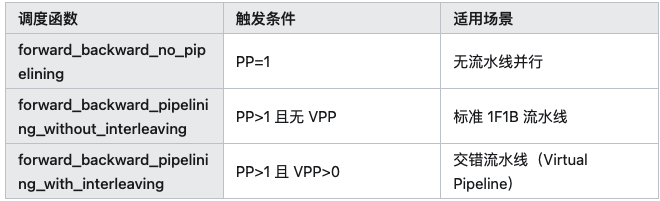

In [20]:
Image(filename='./Image/sft_rl_07.2.png')

verl 侧的唯一调用点在 megatron 引擎内部（transformer_impl.py），无参调用，拓扑从 parallel_state 读取。

关键认知：拓扑（PP/VPP）在引擎初始化时固定，因此同一个引擎进程内，工厂每次调用返回的是同一个函数。不会出现“这次算 log_prob 走一种调度、下次 actor update 走另一种调度”的情况——下文的 MoE 优化子路径也是如此，区别只在于调度器内部走哪条分支。

### 3.1.2 真正的开关：forward_only
RL 的 6 个计算环节最终都汇聚到引擎的同一个入口 MegatronEngine.forward_backward_batch（transformer_impl.py）。如下图所示，这里没有“专门的推理引擎”或“专门的训练引擎”，只有传入的 forward_only 布尔值在起分水岭作用：

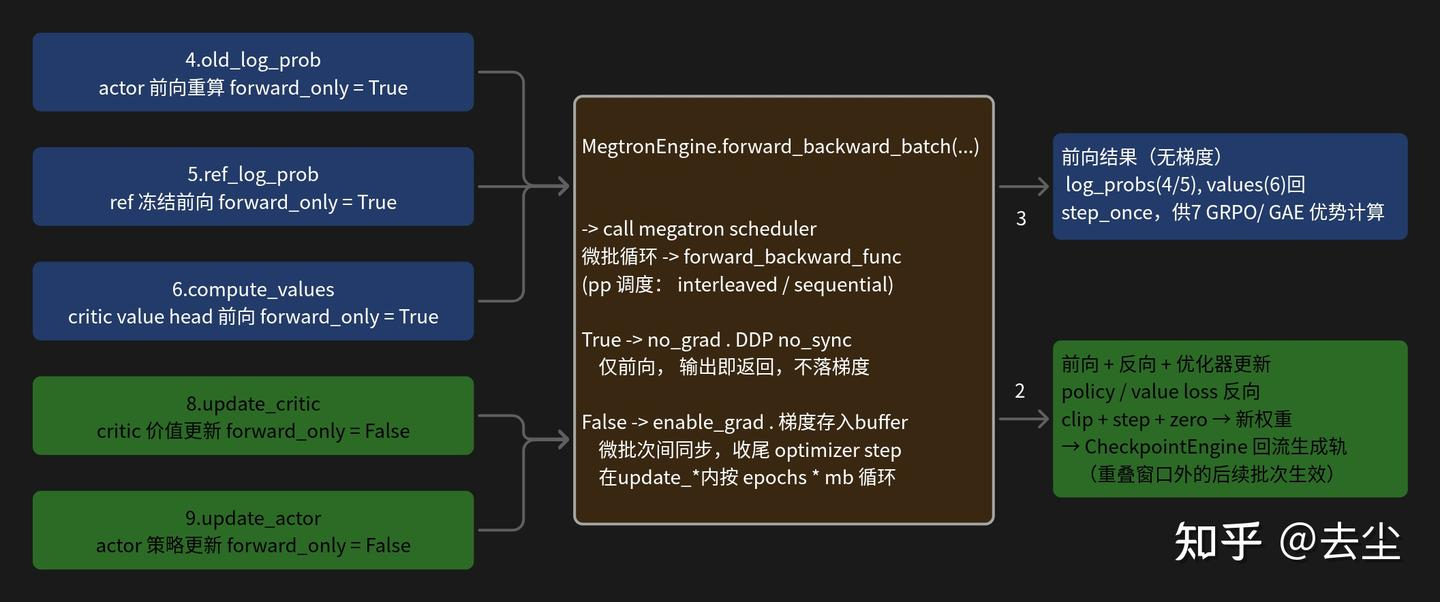

In [21]:
Image(filename='./Image/sft_rl_08.jpg')

引擎在此处调用工厂函数获取调度器，随后传入 forward_only 参数。verl 侧只有两种取值来源（engine/base.py）：

- actor update：train_batch = optimizer_zero_grad → forward_backward_batch(forward_only=False) → optimizer_step
- old_log_prob / ref_log_prob / critic infer：infer_batch = torch.no_grad() → forward_backward_batch(forward_only=True)

以 PP=1 的 forward_backward_no_pipelining 为例（骨架，略去 hybrid_context_parallel 分支与次要参数，schedules.py）：

In [ ]:
# 标准串行模式的骨架
with no_sync_func():
    for i in range(num_microbatches - 1):
        output_tensor, num_tokens = forward_step(...)
        if not forward_only:# megatron/core/pipeline_parallel/schedules.py
if config.overlap_moe_expert_parallel_comm and not forward_only:
    # MoE 通信重叠路径，仅 fwd+bwd 进入，见 3.1.5
    return combined_1f1b_schedule_for_no_pipelining(...)
else:
    with no_sync_func():
        for i in range(num_microbatches - 1):
            output_tensor = forward_step(...)
            if not forward_only:
                backward_step(...)          # forward_only=True 时整体退化为纯前向串行
    # 最后一个 micro-batch 在 no_sync 之外执行，
    # 让 DDP 梯度桶在最后一批反向后自然完成 All-Reduce
    output_tensor = forward_step(...)
    if not forward_only:
        backward_step(...)
            backward_step(input_tensor, output_tensor, output_tensor_grad, config)
# 最后一个 micro-batch 在 no_sync 之外执行（触发梯度同步）

- 关键认知：门控条件里的 not forward_only 意味着——即使开了 MoE 通信重叠，old_log_prob（forward-only）也永远不会进入 combined_1f1b，只会走普通循环。这条路径专属 actor update。


- 边界说明：forward_only 是进入调度器的唯一模式开关；但 RL 调用方同时还切换了 optimizer_zero_grad/step（仅 train）、torch.no_grad（infer）和 eval/train mode。另有一个引擎级配置 engine_config.forward_only（ref/critic 纯推理引擎不包 DDP、不建 optimizer），那是第二套同名机制，勿与调度器参数混淆。

### 3.1.3 PP=1：串行循环
forward_backward_no_pipelining 没有流水线：微批逐个前向、逐个反向，梯度同步靠最后一个微批脱离 no_sync 后自然触发。RL 关心三点：

1. forward-only 时它就是纯前向串行：backward_step 全部跳过，无任何流水线填充开销，吞吐是 DP 并行的线性叠加。
2. num_microbatches 是动态切出来的，不是静态配置：engine 把 micro_batch_size_per_gpu 写入 data（train 用 engine_config.micro_batch_size_per_gpu，infer 用 infer_micro_batch_size_per_gpu，prepare_micro_batches按 总样本数 ÷ (micro_batch_size_per_gpu × 组数) 切块，PPO 的 ppo_mini_batch_size 先均分到 DP 再除以 micro_batch_size。rollout.n 不出现在这个公式里——它决定生成批规模，而 ppo_mini_batch_size 本身就按含 n 的样本数计。
3. old_log_prob 与 actor update 的 micro_batch_size 配置不同，所以两者的 num_microbatches 通常不同。

### 3.1.4 PP>1：1F1B 三段结构与 forward-only 的退化

In [ ]:
# megatron/core/pipeline_parallel/schedules.py
num_warmup_microbatches = pp_group.size() - pp_group.rank() - 1
num_warmup_microbatches = min(num_warmup_microbatches, num_microbatches)

即早期 PP rank 多做几个纯前向（warmup），之后进入“1F1B 稳态”，最后把积压的反向排空（cooldown）。

RL 关心点：forward-only 在这条路上并不“抄近道”。 激活仍要逐级 P2P 接力，后级等前级，填充气泡仍在；只是三段结构里的反向排空退化为纯前向收尾——没有 Cooldown 可言。在同卡数对比下，这套接力开销是 PP=1（等价于纯 DP 切分）所没有的，这是 PP>1 时算 old_log_prob 的固有代价。


而在交错 VPP 调度（with_interleaving）下，Warmup 的计算会经过共享规划函数 get_pp_rank_microbatches。源码中有一段直接针对 forward-only 的处理（schedules.py）：

In [ ]:
# megatron/core/pipeline_parallel/schedules.py
if forward_only:
    num_warmup_microbatches = total_num_microbatches

### 3.1.5 MoE 专项机制：双流通信掩盖与路由回放（R2/R3）
MoE 模型让 RL 复用底座多出两件纯 MoE 才有的问题：EP All-to-All 通信怎么被计算掩盖（Megatron 提供子路径），以及训练前向的路由怎么与记录时保持一致（verl 提供 router replay）。这两个机制都发生在调度器以下——门控在调度器内部、replay 在 forward_step 内部，工厂返回值与调度器骨架均不受影响。

- a）双流通信掩盖：门控条件 overlap_moe_expert_parallel_comm and not forward_only
这条加速子路径（combined_1f1b）不是工厂返回的第四种调度器，而是调度器内部按条件切换的实现。以交错 VPP 调度器为例，如下图所示，主循环函数 forward_backward_helper_wrapper 内部就是一条 if-else 分支：满足门控条件时，执行 combined_1f1b_schedule_for_interleaved_pipelining；不满足时，执行常规的 forward_step_helper / backward_step_helper。

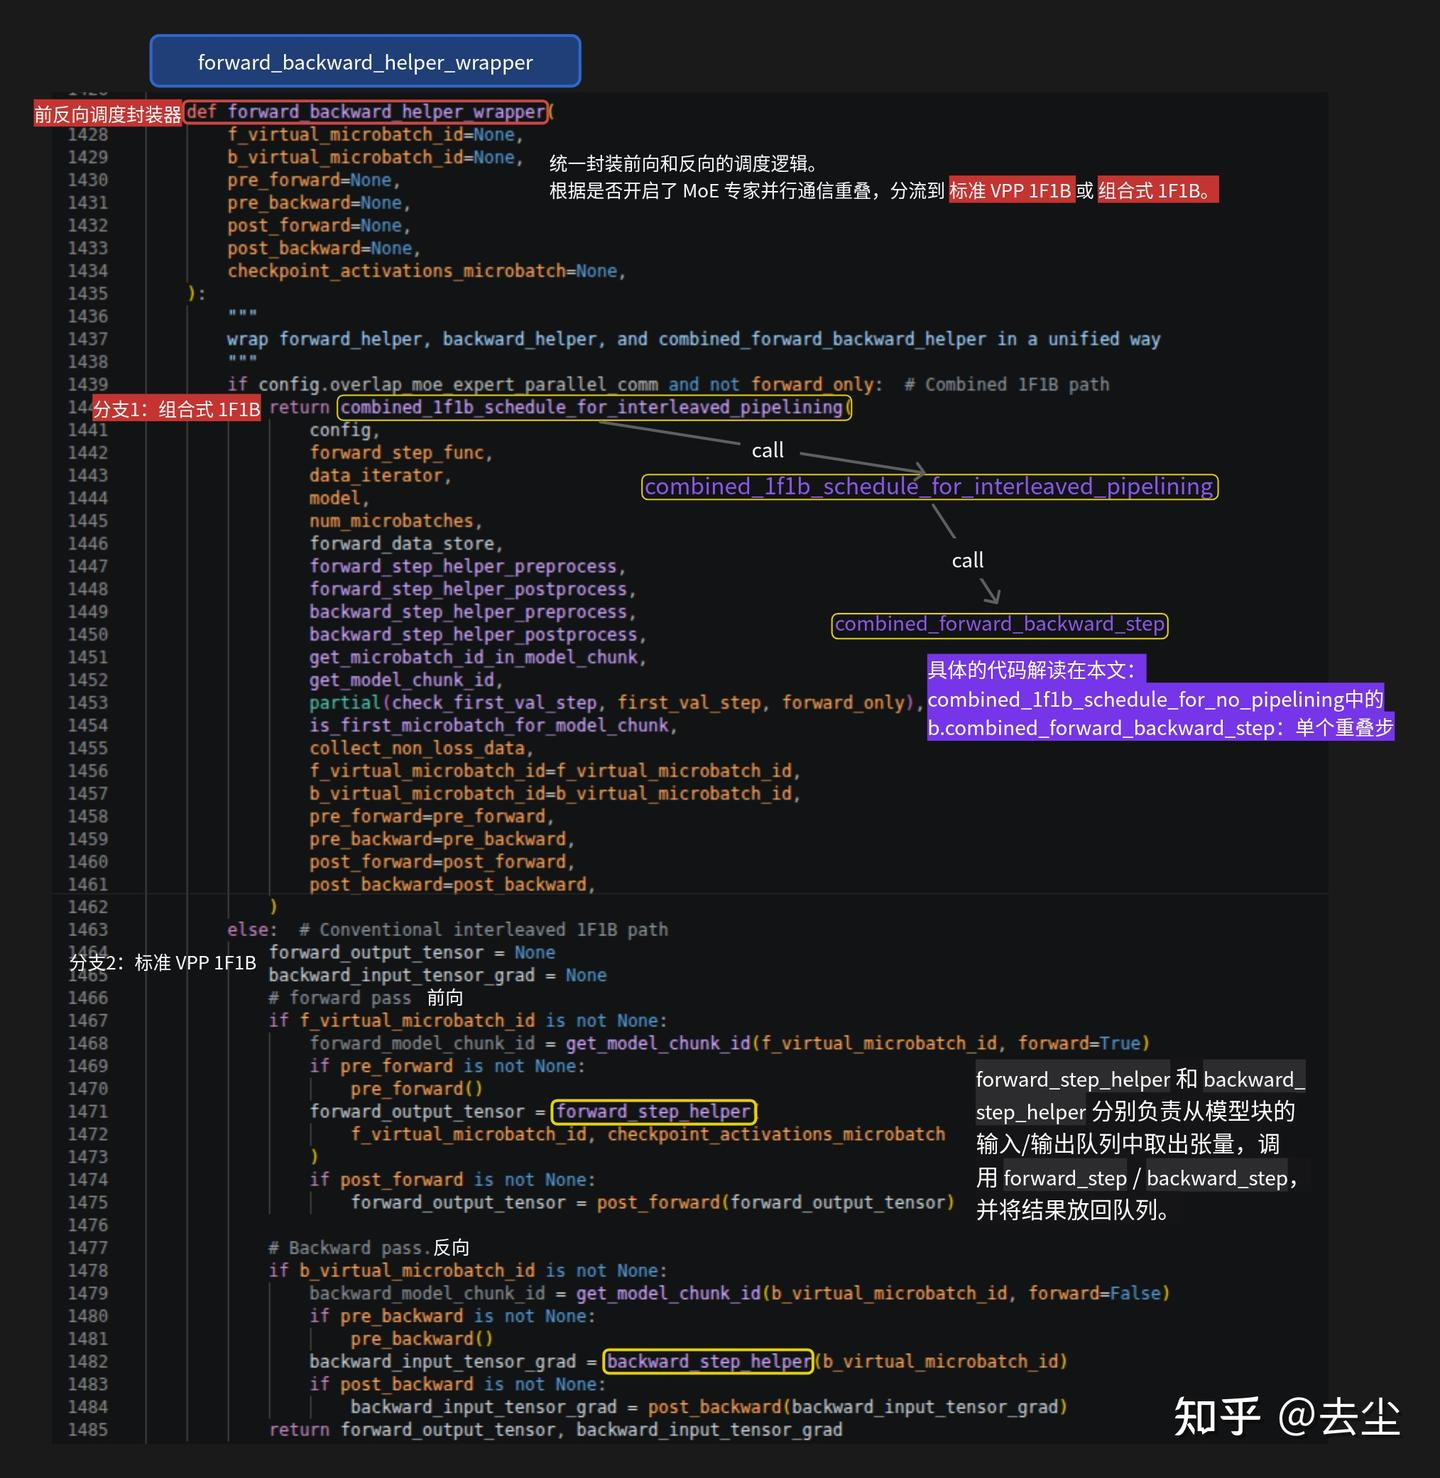

In [22]:
Image(filename='./Image/sft_rl_09.jpg')

overlap_moe_expert_parallel_comm and not forward_only 满足时，才会切入组合式 1F1B。

门控条件的第二项 not forward_only 是理解它的关键：这条路径专属 fwd+bwd（actor/critic update）。原因不在配置而在机制——它的掩盖方式是“微批 i 前向的 EP A2A（dispatch/combine）被微批 i-1 反向的 Attention/MLP 计算遮盖，反之亦然”（combined_1f1b.py docstring 原文）。forward-only 没有反向可供并行，A2A 只能干等计算，掩盖收益不存在。所以 old_log_prob 即使开了这个配置，也走 3.1.3 的普通循环。


双流机制本身：常规 no_pipelining 里微批严格串行，A2A 通信完全暴露在关键路径上；combined_1f1b 改为在微批级做 1F1B，把通信与计算挂到不同 CUDA 流上 co-schedule（set_streams()），通信时长被另一个微批的计算时长吸收。首个微批单独先跑（Phase 0），没有可重叠对象。调度计划由 TransformerModelChunkSchedulePlan.run() 驱动，并要求 forward_step_func 的第一个返回值是 AbstractSchedulePlan 实例；交错版还有一个配套细节——Warmup 额外 +1（schedules.py），确保每个 1F1B 步的前向与反向相互独立。

- b）路由回放 R2/R3：训练前向必须“走老路”
问题背景：actor update 时权重已被梯度更新过，router 本会给出不同的 topk。但 PPO 要求训练前向的计算图与当初产生这些 token 的前向一致——MoE 下这意味着逐层沿相同的专家路由走，否则：
- (i) 重算的概率失真、PPO 目标失效；
- (ii) EP All-to-All 的 dispatch 形状随路由改变。
router replay 就是强制训练“走老路”的机制。如下图所示，在 forward_backward_batch 的入口处，引擎会设置全局的 RouterReplayAction：

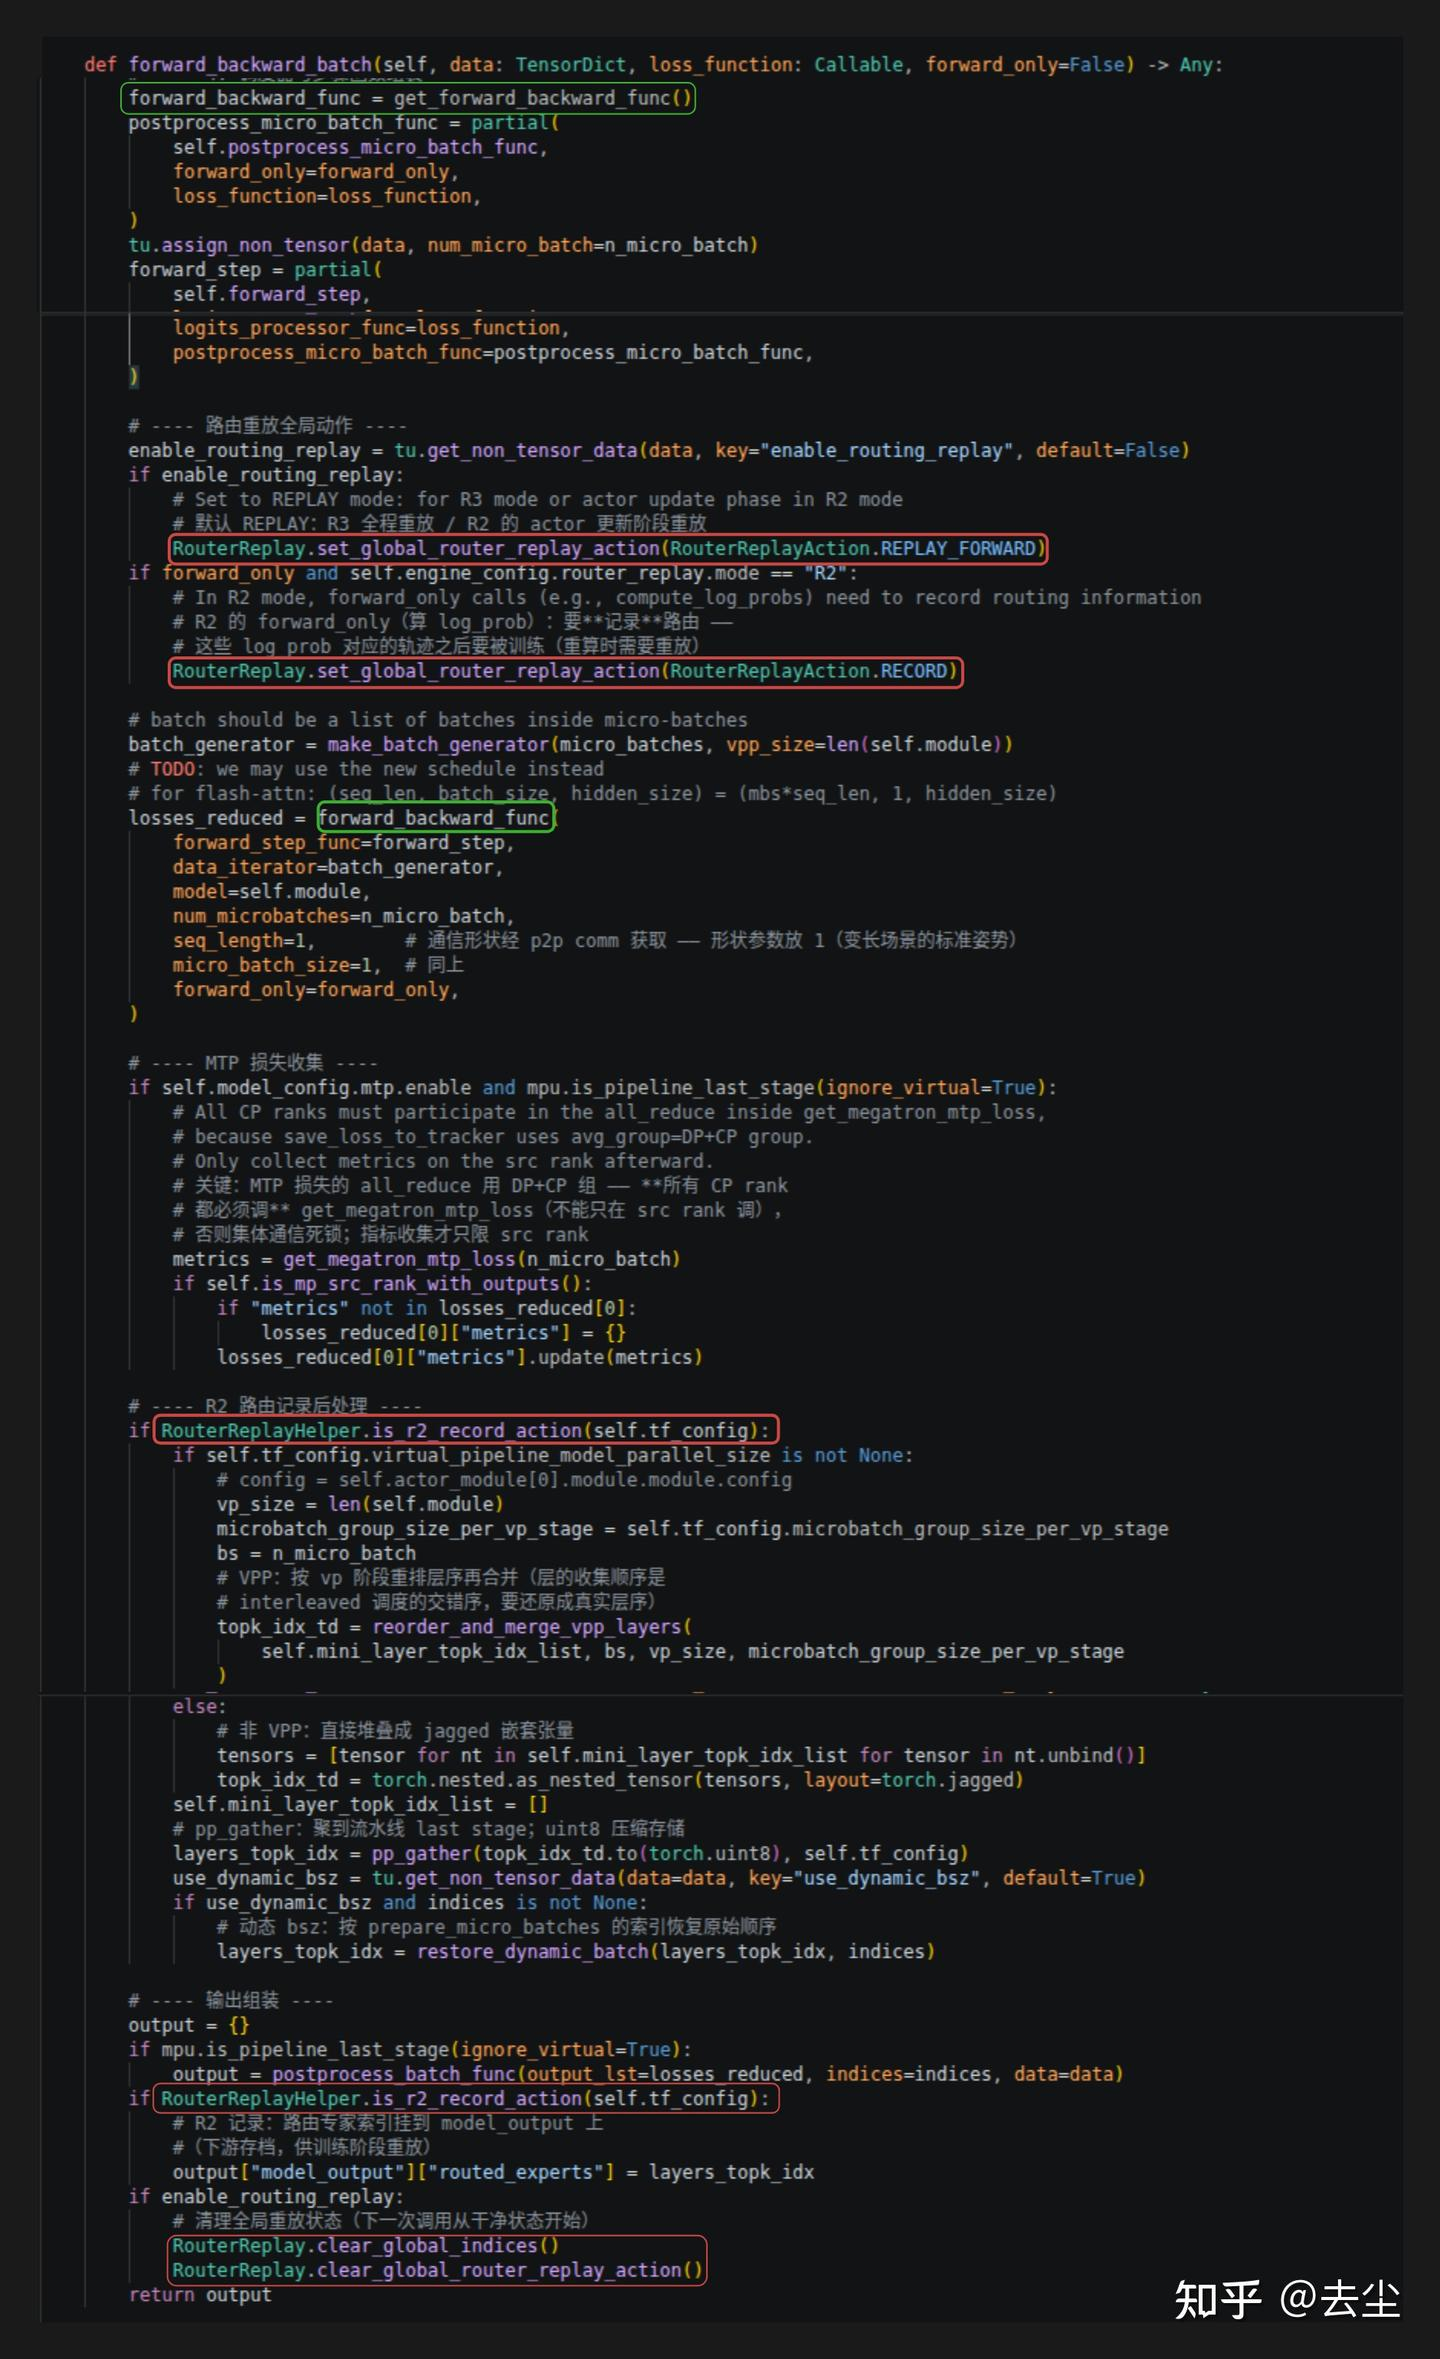

In [23]:
Image(filename='./Image/sft_rl_10.jpg')

实现上有三态动作 RouterReplayAction（router_replay_patch.py）：RECORD / REPLAY_FORWARD / REPLAY_BACKWARD。前向回放时把记录的 topk 填回各层 router 并暂存，反向回放时逐层弹出沿用。verl 的接线只有一处（transformer_impl.py）：每次进入 forward_backward_batch 时设置全局动作——训练调用（actor update）恒为 REPLAY_FORWARD；R2 模式且 forward_only（old_log_prob）则改为 RECORD。mode 读自 actor 引擎配置（engine_workers.py）。

  - R2：训练引擎内闭环。 记录者是训练引擎自己的 forward-only 前向——RL 中即 old_log_prob；topk 存在该进程内存里，随后 actor update 的前向回放、反向沿用。图下半部分所示，在 R2 模式下，forward_backward_batch 执行完后，会将记录的 layers_topk_idx 收集并挂载到 output[“model_output”][“routed_experts”] 上，最后清理全局状态，等待下一次调用。隐含约束：old_log_prob 与 actor update 必须在同一个引擎进程内。
  - R3：rollout 侧捕获。 路由由 rollout 侧记录（docstring “rollout-captured routes”），训练侧经 set_router_replay_data（router_replay_utils.py）把 [bs, seq, layer, topk] 的路由张量按序列并行 rank 散射注入各层 RouterReplay。回放范围由 build_r3_replay_mask构建：除最后一个 response 行外整段回放——因为 response 的 logprob 取自移位后的模型行，而这些行 attend 到更早的 hidden states，那些位置的 MoE 路由同样影响结果；只有最后一行的 logits 不被下游消费，不回放。掩码为 True 的 token 强制走回放路由，False 的走 Megatron 原生路由。R3 不依赖同进程闭包，适合 rollout 与训练分离部署。 正交性：router replay 与 combined_1f1b 是两件独立的事——前者管“路由跟谁对齐”，后者管“通信怎么被掩盖”，可同时启用。old_log_prob 在 R2 下承担记录职责，并不需要也不允许进入 (a) 的重叠路径（not forward_only 已把它挡在外面）。

### 3.1.6 小结：RL 通过 forward_only 和 batch size 切换”契约”

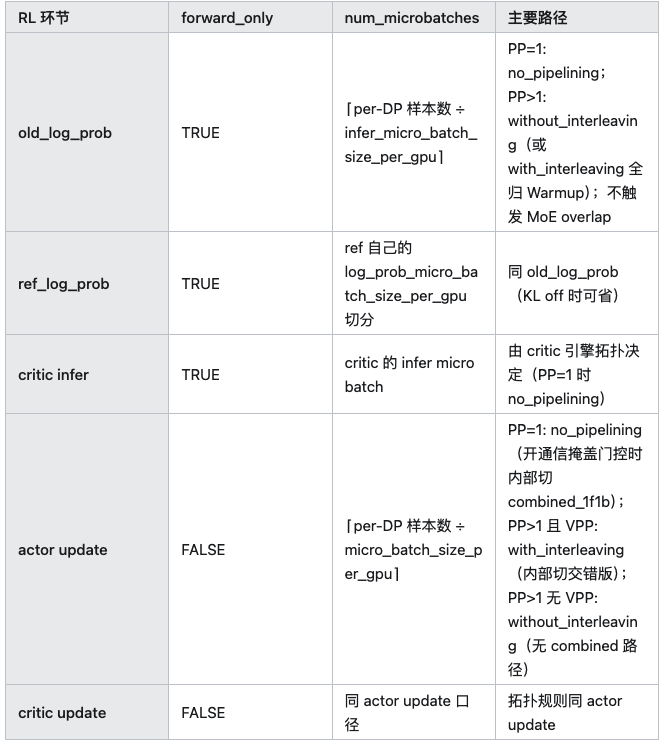

In [24]:
Image(filename='./Image/sft_rl_10.1.png')

RL 没有改调度器一行代码。 从宏观上看，RL 的多次前向/反向本质上只有两种执行模式（forward_only=True/False）；所谓“不同的调度”，只是 Megatron 面对 PP/VPP 拓扑时为掩盖通信延迟而衍生的底层变体——RL 复用的是这一个工厂和它返回的那一个函数，切换的只是那一个布尔值。MoE 专属的 combined_1f1b 和 Router Replay 则是引擎在拿到这个布尔值后，在微观算子层做出的极致优化。

##  接口 B：Loss 注入点 —— forward_step_calc_loss 的契约与 verl 的 loss_fn
这一节讲什么：调度器从不自己算 loss。它收下一个二元组 (output_tensor, loss_func)，在最后一个 PP stage 用统一的收尾逻辑调用注入的闭包——这个槽位就是“接口 B”。SFT 时代槽位里装的是 CrossEntropy；RL 时代 verl 用自己的后处理函数填了它，RL 的各种 Policy Loss 在后处理内部被消费。

### 宏观契约：二元组与调度器的收尾职责
forward_step（schedules.py:415-421）在模型前向跑完后返回 (output_tensor, loss_func)，调度器随即调用 forward_step_calc_loss。它只在最后一个流水线阶段工作，做四件事：

1. 调用注入的闭包：outputs = loss_func(output_tensor)。现代协议接受三元组 (output_tensor, num_tokens, loss_reduced)；旧版二元组走 legacy 分支（output_tensor *= cp_group_size; /= num_microbatches）。collect_non_loss_data=True 时改调 loss_func(output_tensor, non_loss_data=True) 收集纯数据（推理评估用）。
2. 归一化（注意分支方向）：calculate_per_token_loss=False（默认）时，output_tensor /= clamp(num_tokens, min=1) 再 /= num_microbatches——先微批内按 token 均值、再跨微批均摊，clamp 是全 mask 防零保护；calculate_per_token_loss=True 时调度器不除，未归一 loss 直通梯度，全局分母由 finalize_model_grads 对 All-Reduce 后的 num_tokens 完成梯度除法（衔接 3.2.5）。
3. 辅助 loss 缩放：MoE 门控是 num_moe_experts is not None，经 config.grad_scale_func 取标量后 MoEAuxLossAutoScaler.set_loss_scale(loss_scale * cp_group_size / num_microbatches)（:274-287）；MTP 同理走 MTPLossAutoScaler（:290-302）。
4. 把 loss_reduced 与 num_tokens 返回给调度器，进入 forward_data_store / 分母协议。

### verl 侧：loss_fn 的注入、双重身份与最终消费
如图所示，RL 的接入全链（transformer_impl.py）如下：

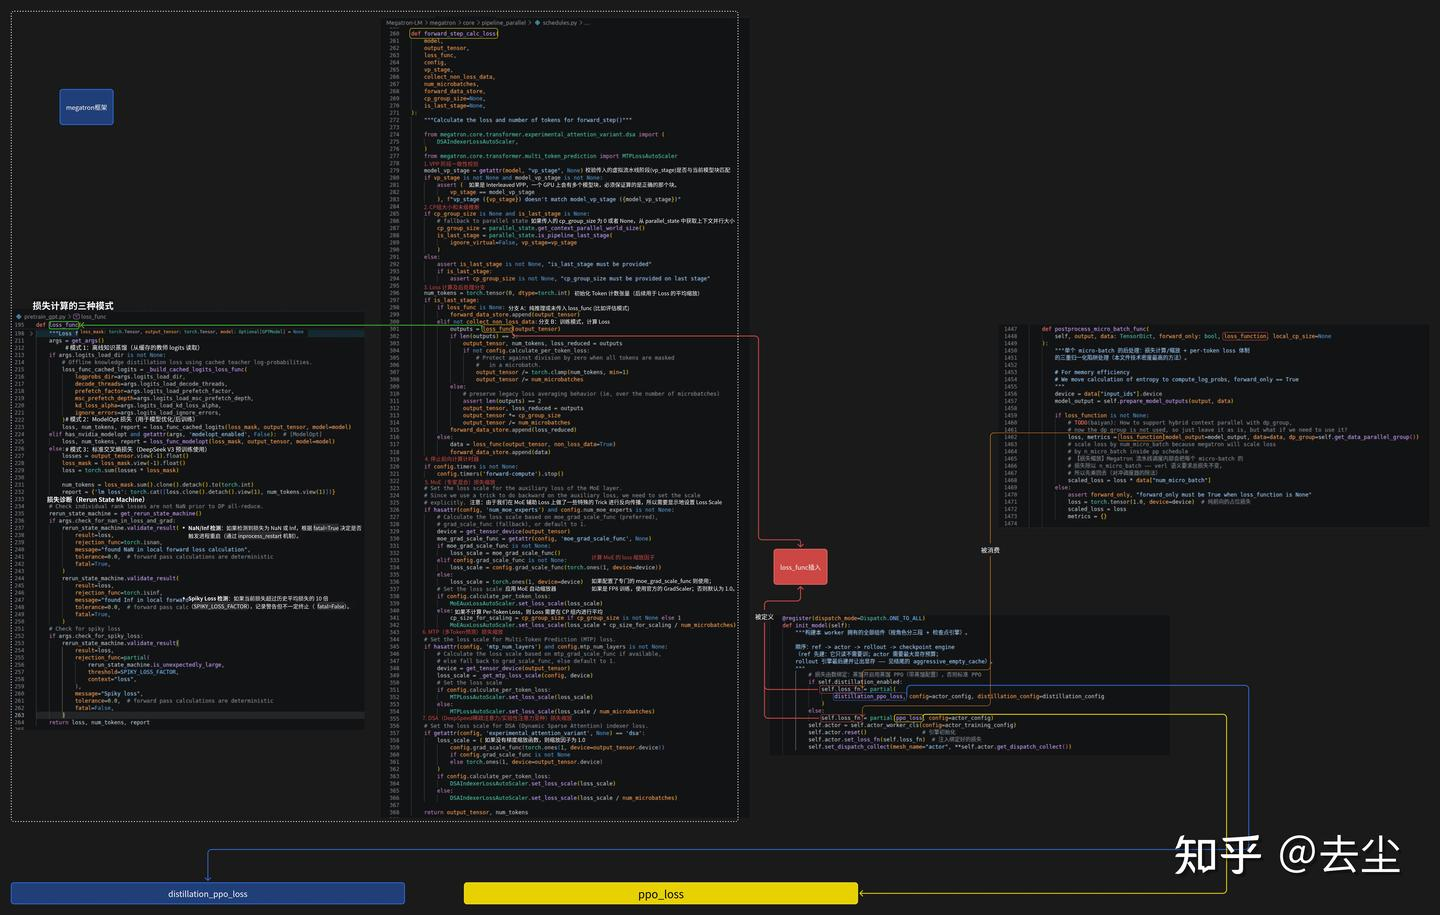

In [25]:
Image(filename='./Image/sft_rl_11.jpg')

从 Trainer 的注册表，到引擎包装，再到 Megatron 调度器中的实际消费。

  - 注册：worker 层 set_loss_fn（engine_workers.py）——actor 注册 policy loss、critic 注册 value loss、蒸馏场景注册蒸馏 loss；self.loss_fn 是 worker 的成员。
  - 引擎 API：forward_backward_batch(data, loss_function, forward_only)——loss_function 是引擎方法的一等参数。train_batch 必传；infer_batch 按 compute_loss 传或传 None。
  - 双重身份：同一个 loss_function 既绑进 postprocess_micro_batch_func，又作为 logits_processor_func 传入 forward_step——它在模型前向内部融合 logprob 计算（不落全词表 logits，省显存；entropy 也移到 forward-only 路径算）。
  - 填契约槽位：verl 的 forward_step 返回 (output, partial(postprocess_micro_batch_func, data=batch, local_cp_size=…))——megatron 契约里的 loss_func 槽位，装的是 verl 的后处理函数。
  - 最终消费：调度器最后 stage 调 loss_func(output_tensor) 时，实际执行 postprocess_micro_batch_func：loss, metrics = loss_function(model_output=model_output, data=data, dp_group=…)；随后 scaled_loss = loss * data[“num_micro_batch”]——预乘微批数，抵消 megatron 稍后的 /num_microbatches。
  - 推理半契约：loss_function=None 时断言 forward_only 并返回占位 loss=1.0——old_log_prob/ref/critic infer 没有 loss，但调度器契约要求闭包必须可调用、必须返回三元组。
关键认知：verl 没有改 megatron 的 loss_func.py，也没把 ppo_loss 塞进 CE 分支——它把接口 B 的槽位整体换成自己的后处理，再在后处理里消费自己注册的 loss_fn。megatron 原生三种 loss 模式对 RL 完全不可见。

### 3.2.3 RL 的 loss 家族：注册表驱动

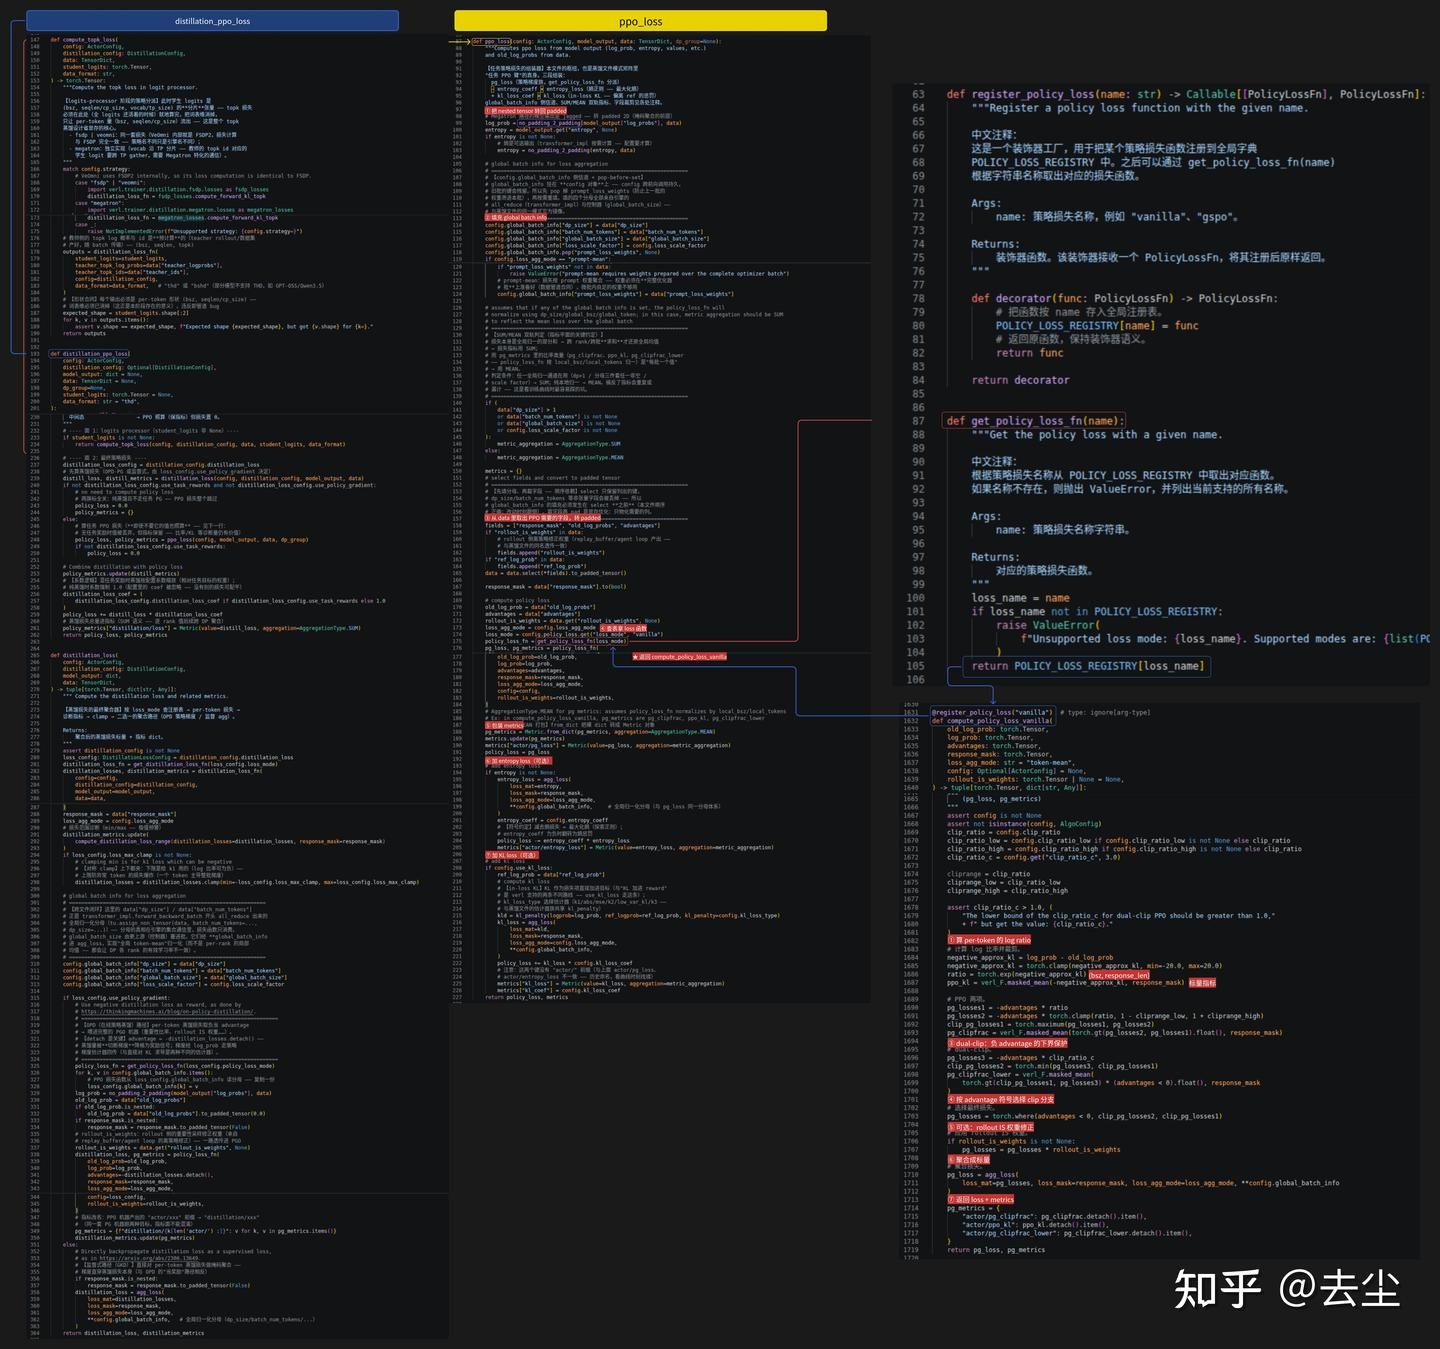

In [26]:
Image(filename='./Image/sft_rl_12.jpg')

回到图的下半部分，我们可以看到 RL 的 Loss 到底长什么样，以及它是如何被动态选中的：

- Policy loss（verl/trainer/ppo/core_algos.py）：register_policy_loss/get_policy_loss_fn注册表驱动，compute_policy_loss为基线，已注册变体：vanilla、dppo_tv、dppo_kl、gspo、sapo、gpg、clip_cov、kl_cov、geo_mean、dro。换算法 = 换注册名，infra 零改动——这正是接口 B 的价值。
- 蒸馏 loss（verl/trainer/distillation/losses.py）：distillation_ppo_loss、topk_loss，注册名含 forward_kl_topk 及 KL 估计器家族 kl/k1/abs/mse/k2/low_var_kl/k3。蒸馏与 PPO 在同一个 loss_function 槽位上组合（distillation_ppo_loss = 蒸馏项 + PPO 项）。
- Value loss（critic）走同一 set_loss_fn 入口（v1/trainer_base.py）。


### 3.2.4 全局分母协议：RL 为什么这么容易“梯度爆炸”？
在 SFT 里，就算需要做 per-token 归一化，全局分母也是在计算图内单一来源处理好的。但在 RL 中，由于序列长度变化剧烈，num_tokens 变成了一个全局协议。这引出了 RL Infra 里最反直觉的失败模式——grad_norm 无故到 1e4 量级，十有八九是分母协商出错，而不是梯度真的爆了。
这个全局协商发生在 finalize_model_grads.py：

In [ ]:
# megatron-core finalize_model_grads.py:543-562
if num_tokens is not None:
    # 1. 从 PP 最后 stage 广播到其他 rank（因为只有最后一级才知道真实的 token 数）
    last_rank = get_pp_last_rank(pp_group)
    torch.distributed.broadcast(num_tokens, src=last_rank, group=pp_group)
    # 2. 跨 DP ranks all-reduce，汇总全局总 token 数
    torch.distributed.all_reduce(num_tokens, group=dp_cp_group)
    # 3. Clamp to avoid div-by-zero without a host-side branch (会破坏 CUDA graph capture)
    safe_num_tokens = torch.clamp(num_tokens, min=1)
    scaling = 1.0 / safe_num_tokens
    # 4. 把真实的全局分母，作为缩放系数乘到所有模型分片的梯度上
    for model_chunk in model:
        model_chunk.scale_gradients(scaling)

注意这段的每一行都在处理 SFT 里没有的复杂度：不仅要做 PP 广播 + DP-CP All-Reduce，甚至为了兼容 CUDA Graph 连一个简单的 if num_tokens == 0 的 host 分支都不敢写，只能用 clamp(min=1)。

verl 把这条链踩过的坑写成了护栏注释（transformer_impl.py）：

  - CP>1 时，Megatron-Bridge 自动开 calculate_per_token_loss，要求 loss_func 返回三元组——若退化成二元组，total_num_tokens=0，MoE router 预乘 num_tokens 的 aux/z loss 永远不会被 finalize 的梯度除法取消，直接体现为 ~1e4 的 grad_norm。
  - seq-mean-token-mean 与 per-token 模式不兼容（逐序列 1/n_s 用 CP 局部分母）。
  - BSHD 不开 remove_padding 时，MoE router 用含 padding 的 B*S 归一化 aux loss。
  - 返回的 num_tokens 还要 //cp_size——真实 token 数在 CP rank 间复制，不除则 DP×CP 求和多算 cp_size 倍。 这就是为什么说 RL 的分母是“全局协议”——每一项 loss 都必须在 3.2.1 抛出 num_tokens 后，经过跨卡协商、缩放抵消、限制约束，才能安全地回传。你原稿“grad_norm 无故到 1e4”的反直觉失败模式，这里是它最具体的机制版本。

## 3.3 接口 C：optimizer.step() —— 三态链 vs 统一 buffer
这一节讲什么：在 SFT 中，optimizer.step() 走完内部的三态链，闭环就结束了。但在 RL 中，由于权重不仅要给训练侧用，还要跨网给推理侧用，这就硬生生逼出了“第四态”的导出问题。
### 3.3.1 经典链：MixedPrecisionOptimizer 的三态
如下图所示，在 SFT 时代标准的优化器闭环中，底层的物理张量经历了极其精密的三个状态转换：

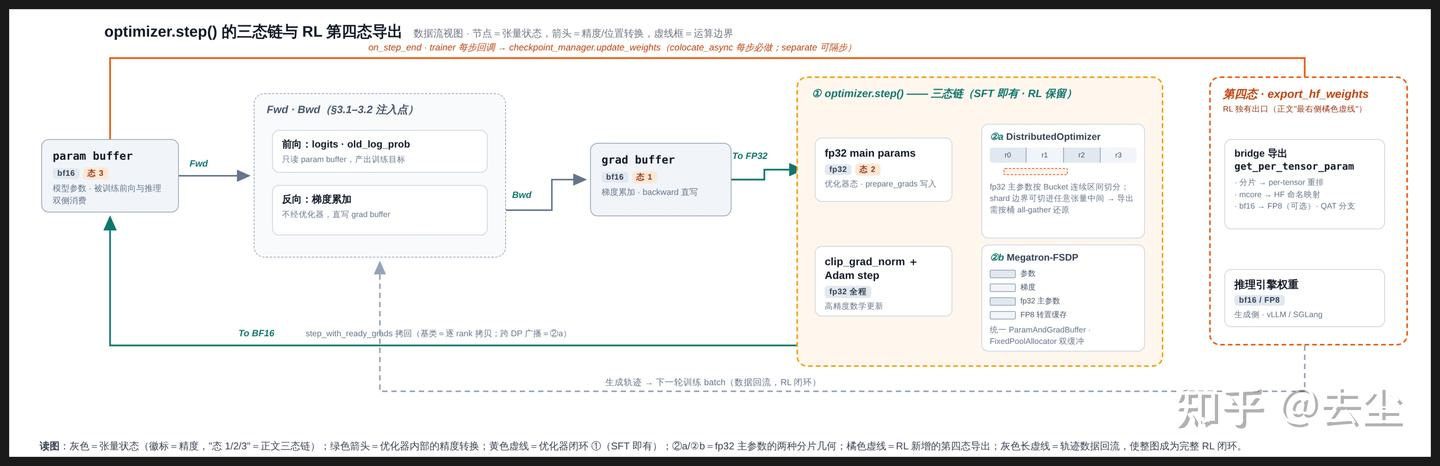

In [27]:
Image(filename='./Image/sft_rl_13.jpg')

In [ ]:
# megatron-core optimizer.py:552-563, 621-637（逐字）
class MixedPrecisionOptimizer(MegatronOptimizer):
    @torch.no_grad()
    def step(self):
        found_inf_flag = self.prepare_grads() # 把模型梯度拷到主梯度
        if found_inf_flag:
            return False, None, None
        ...
        grad_norm = self.clip_grad_norm(self.config.clip_grad)
        ...
        success = self.step_with_ready_grads() # 把 fp32 主参数广播回 param buffer
        return success, grad_norm, num_zeros_in_grad

三态是：

1. grad buffer（bf16 累加，态 1）——backward 阶段直接写入的梯度。
2. fp32 main params（优化器态，态 2）——prepare_grads 把梯度拷进 fp32 主参数做高精度更新。基类持有的是全量 fp32 副本；“切成分片存到 optimizer 里”是 ②a DistributedOptimizer 的增强行为，不是这段代码本身的语义。
3. param buffer（bf16 模型参数，态 3）——step_with_ready_grads 把更新好的 fp32 主参数拷回 param buffer。基类是逐 rank 拷贝；跨 DP 的“广播”同样要等 ②a。

RL 的新增动作：看图最右侧虚线的“第四态”。 触发点不在 optimizer 内部，而是 trainer 的每步回调：每个训练 step 收尾时 on_step_end() 被调用（trainer_base.py，紧跟 save_checkpoint 之后）。colocate_async 模式下它做两件事：checkpoint_manager.update_weights(global_steps) 唤醒所有副本更新权重，然后 resume_generation_replicas() 恢复生成（trainer_colocate_async.py）。真正的“导出”发生在 sync 链下游：训练引擎的 get_per_tensor_param（transformer_impl.py）经 Megatron-Bridge 产出 per-tensor 的 HF 命名权重——vanilla_bridge 走 bridge.export_weights，LoRA adapter-only 走 bridge.export_adapter_weights，默认走 bridge.export_hf_weights——再流式发给推理引擎。SFT 的 param buffer 只被训练前向消费，没有这条出口。

### 3.3.2 分片几何：DistributedOptimizer 的按桶切分
看图里的 ②a：DistributedOptimizer 在处理 fp32 主参数时，是不看张量边界的，它是按连续区间（Bucket）切分的：

In [ ]:
# megatron-core distrib_optimizer.py
if hasattr(model_param, 'get_high_precision_init_val'):
    shard_main_param = (
        model_param.get_high_precision_init_val()
        .view(-1)[param_range.start : param_range.end] # 直接切连续区间
        ...
    )
else:
    shard_main_param = shard_model_param.clone().float()

这带来了两个极其致命的后果（也是第 6 章的根源）：

Reduce-scatter 是按桶走的：通信量和 bucket 的大小有关，跟 PPO mini-batch 的微观梯度结构毫无关系。
导出必须重排：看图里 ②a 的橘色虚线框——桶以“整参数”为边界，一个参数不会跨两个桶；真正被切断的是每个 DP rank 持有的连续分片区间，区间边界可以切在任意张量中间。所以导给推理引擎时，必须按桶 all-gather 还原完整张量，再按 HF tensor 重新切分。

### 3.3.3 统一 buffer：Megatron-FSDP 的“极端压缩”
看图里的 ②b：面对万亿 MoE 模型，DistributedOptimizer 的碎片化太严重了。Megatron-FSDP 换了一种思路——把参数、梯度、fp32 主参数、甚至 FP8 的转置缓存，全部塞进同一个巨大的 ParamAndGradBuffer 里。
verl 里 Megatron-FSDP 有两个真实入口：

 - megatron 引擎内：以 mcore 适配器同位替换 DDP——from megatron.core.distributed.fsdp.mcore_fsdp_adapter import FullyShardedDataParallel（megatron_utils.py，包不可用时回退 DDP）。
 - automodel 引擎：策略 strategy="megatron_fsdp"，from megatron_fsdp.fully_shard import fully_shard_optimizer（automodel/utils.py），配置项 use_megatron_fsdp（注释即 "Zero-3 sharding"，config/engine.py）。

In [ ]:
# megatron_fsdp/param_and_grad_buffer.py FixedPoolAllocator（结构示意；本环境无该包，无法逐字核对）
def __init__(self, name, fsdp_param_groups, size=2, fallback_to_persistent_buffer=False):
    ...
    # 识别哪些 FSDP 单元共享同一 buffer storage
    fsdp_units_to_double_buffer = []
    ...
    self.size = size  # 默认双缓冲

Megatron-FSDP 和经典 DistributedOptimizer 的本质区别：

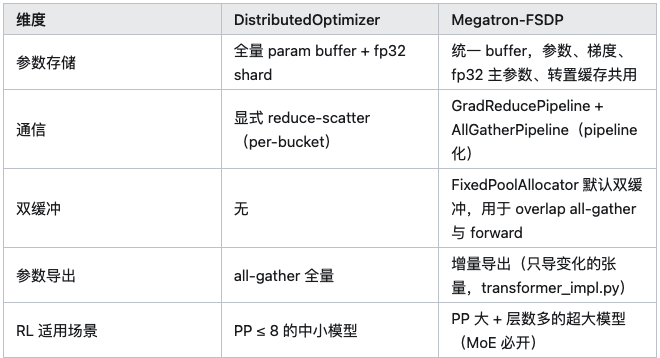

In [28]:
Image(filename='./Image/sft_rl_13.1.png')

RL 关心什么：真实存在的重叠开关是 overlap_param_gather——它是 mcore OptimizerConfig 的属性（optimizer.config.overlap_param_gather，megatron_utils.py），配合 ddp_config.align_param_gather 决定是否给前向挂上 config.param_sync_func（每个 model chunk 的 start_param_sync）；megatron_FSDP | DDP 模型共用这条路径。它管的是训练前向期间参数 all-gather 与计算的重叠时机。

### 3.3.4 第四态：export_hf_weights 的代价
回到图里最右侧的橘色虚线。SFT 的 param buffer 只要自己训练闭环就好；但 RL 的 param buffer 必须同时被双侧消费：训练侧拿它做下一次 fwd，推理侧拿它去生成。
因为两侧的底座不同、并行拓扑不同，就产生了极其痛苦的“三层不一致”（这是第 6 章的核心）：

1. 命名空间：mcore 层路径 vs HF 层命名（靠 bridge 真值表解决）。
2. 切分几何：Bucket 连续区间 vs HF per-tensor 切分（靠重排/增量导出解决）。
3. 精度：训练侧的 bf16 权重 vs 推理侧的 FP8——FP8 rollout 是可选配置，不是必然；同一条导出链上还有 QAT/ModelOpt 的量化导出分支（_qat_enabled → export_qat_weights，transformer_impl.py:857-861），“靠量化对齐解决”指的就是这一族机制。

结论：per-tensor 导出是同步策略要求时的额外通信——colocate_async 下每步必做，separate 模式可隔步——它完全不在 SFT 的 critical path 上，但常被视为 RL Infra 中除 Rollout 之外最大的性能黑洞之一。

## 结论：SFT 底座是”铁打的营盘”，RL 是”流水的兵”
如果把这三条接口的差异浓缩成一张表，会发现一个令人震撼的事实：RL 的“学习”这一步，在 Megatron-Core 内部与 SFT 是逐字节相同的。

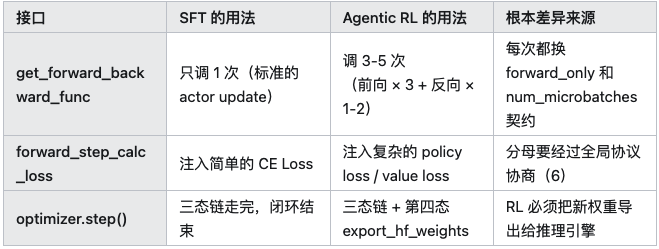

In [29]:
Image(filename='./Image/sft_rl_13.2.png')

结论先行：

三种调度器的选择逻辑、loss 注入的契约、fp32 主参数的流转、梯度分片的统一 buffer——RL 全部原样复用，一行没改。

RL Infra 的新增复杂度不在 core 内部，全部长在“框间”的三处缝隙里：

1. 调用频率：从 1 次变 3-5 次，算子被反复热启。
2. 第四态导出：训练侧的权重必须跨越物理网络，翻译成推理引擎认识的形状。
3. 第四态的一致性：两份权重真相之间，隔着格式、切分、精度三层鸿沟。

Megatron 这套强大的 SFT 底座，就像一座“铁打的营盘”，为模型的学习提供了无坚不摧的算力支撑；而 RL 的各种前向调用、异步流水线和权重推流，则是那“流水的兵”，围绕着这座营盘穿插游走。

带着这个认知，我们正式进入第 4 章：看看这些“流水的兵”，是如何在 RL 循环中排兵布阵的。

# 4. RL 循环：四件套的复用、变形，加一个新生框
这一节讲什么：回顾 1.2 章节，RL 的拓扑不仅有训练（框 A）和推理（框 B），还多出了一个奖励框（框 C），以及连接它们的轨迹、权重、版本三条边。本节将沿着这三条边，拆解 Rollout 产出的“带工具调用的复杂多轮数据”如何流经奖励框，被翻译成 Token 级权重，并最终喂给训练框。

## 4.1 一次迭代的三方交接

In [ ]:
# trainer_base.py:_step_once（节选）
def _step_once(self, metrics: dict, timing_raw: dict, sample_batch_size: int) -> KVBatchMeta:
    # 1. sample batch from replay buffer (gen)
    # 2. [OPTIONAL] compute reward score with colocated reward model
    # 3. balance batch across data parallel groups
    # 4. compute old_log_prob
    # 5. [OPTIONAL] compute ref_log_prob
    # 6. [OPTIONAL] compute critic values
    # 7. compute advantage and return
    # 8. [OPTIONAL] update critic
    # 9. update actor

每一次 _step_once（verl/trainer/ppo/v1/trainer_base.py:797），本质上都是三个框在时间轴上的一次握手：

1. 轨迹边（Rollout → TQ → Reward）：Rollout 引擎（vLLM/SGLang）处理完复杂的 Agentic 会话，把轨迹写入 TransferQueue（TQ）。注意，这里的轨迹不是简简单单的文本，而是包含了思考（\<think>）、工具调用（\<tool_call>）和观测结果（observation）的交错序列。步骤 1 对应源码里的 gen 计时器：从 TQ 拉取数据；如果是 sync 模式，步骤 1 末尾的 on_sample_end 还会触发 vLLM 的 sleep（让出显存）。
2. 打分与翻译（Reward 框）：奖励框（Reward Loop）从 TQ 捞出这些数据（_compute_reward_colocate 里的 tq.kv_batch_get，trainer_base.py:1642-1644），根据不同的策略（规则匹配、沙盒执行、判别模型、生成模型）计算得分，并把标量分数“膨胀”成 Token 级张量，写回 TQ。
3. 训练边（Reward → TQ → Train）：训练框（Megatron）捞取包含 response_mask、old_log_prob 和 rm_scores 的完整 Batch，算出 Advantage，完成梯度更新。
注意（图里的隐藏危机）：这三者并不是完美的流水线。因为 Reward 框的计算往往极其耗时（比如跑代码沙盒、调大模型），这直接导致了 sync 模式下的长时间空转，或者 separate_async 模式下不可避免的 staleness。

为什么 Reward（步骤 2）和 balance（步骤 3）要排在 old_log_prob（步骤 4）之前？两个可核实的原因：

- (1) 显存窗口——共卡 RM 要借“Rollout 已睡、Actor 未醒”的空档完成 wake_up/sleep 体操（4.4 详述），必须赶在步骤 4 的 Actor 前向之前；

- (2) 数据划分——balance 把样本按 DP 组重排，之后的前向（步骤 4–6）与更新（步骤 8–9）都跑在均衡后的划分上。注意 verl 并不会因为“reward 全 0”而跳过 old_log_prob 的重算——按组过滤（algorithm.filter_groups）发生在采样期且要求 rule-based reward（trainer_base.py），不在 _step_once 里。

## 4.2 奖励框的全面解剖：它到底有几种面孔？
Reward 模型是当前后训练研究的重中之重——这个判断在 2026 年有了新的注脚：grader compute 已经从“Rollout 之外的附加项”变成了与 Rollout、Training 并列的第三根算力支柱。MiMo-V2.6-Pro 的一次完整 RL 训练里，rollout 占 43.8%、training 占 43.5%、grader 单独吃掉 12.7%——这个比例足以让“奖励框只是个附属组件”的旧认知彻底失效。

在 verl 的物理实现里，Reward 框是一个可以横跨 CPU、网络和各种自定义沙盒的泛化组件。它主要分为以下四类：

### 4.2.1 类型一：Rule-based（规则/工具验证）—— 纯 CPU 计算，但覆盖面已远超“数学题 + 代码题”
最经典的形态：对于数学题、代码生成，直接把 Rollout 生成的代码丢进 Docker 沙盒运行单元测试，或者用正则提取 GSM8K 的答案并对比。

2026 年的扩展是，Rule-based 验证已经从“判对错”扩展到了 agentic 任务的确定性验证。以 CyberGym 为例：它的公开评分只考一件事——PoC 复现。智能体拿到的只是漏洞的文字描述和未修补代码库，生成的 PoC 必须同时满足两个执行条件：

（1）在未修补构建上触发 sanitizer 崩溃；

（2）在已修补构建上不触发任何崩溃。

第二步正是“区分同一漏洞与任意崩溃”的机制：它保证 PoC 精确复现的是补丁所修复的那个漏洞，而不是碰巧踩中别的 bug。验证全程运行在 sanitizer 插桩的隔离容器中，指标为 PoC 成功率。基准的 Level 0–3 是给 agent 的信息量档位，不是评分流水线的阶段。DeepSeek-V4.1-Flash在其上报告的分数，是这一公开基准下的结果。

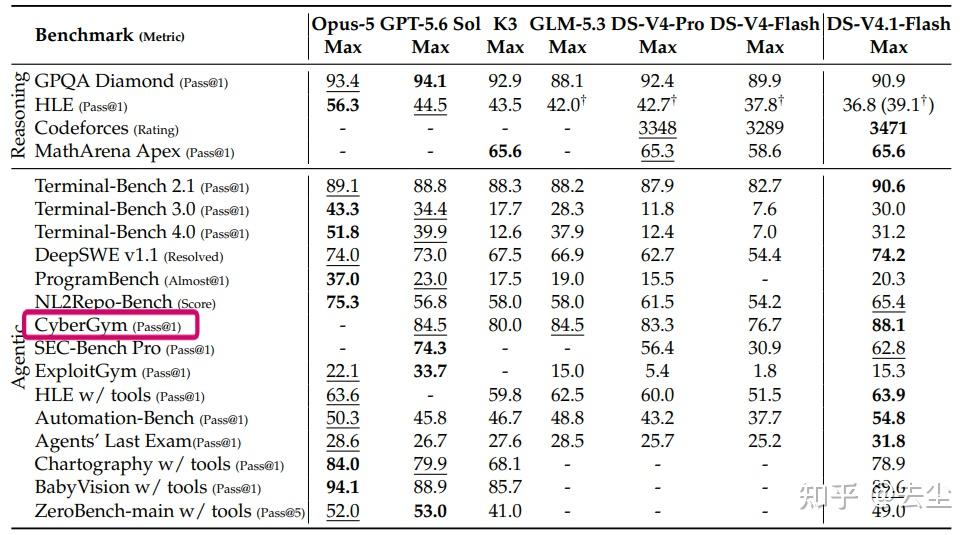

In [30]:
Image(filename='./Image/sft_rl_14.jpg')

至于训练时是否使用“sanitizer 报告属性抽取 + 字符串匹配”作为 reward，属于未公开的内部实现——公开材料只能确认 CyberGym 的验证基于 sanitizer 崩溃签名，不能推断训练 reward 的具体构造方式。

  - Infra 表现：完全在 CPU 上执行，可以异步进行，不占用推理显存。代价是任务构造阶段的工程量——要把每个任务的可验证条件写成确定性规则，而不是让模型自由发挥。
### 4.2.2 类型二：Discriminative RM（判别式模型）—— 经典池化
传统的打分模型（如 Llama-Guard）。把 prompt + response 喂给模型，取最后一个 Token 的隐层输出过一个分类头。

  - Infra 表现：在 verl 里，它请求的是 vLLM/SGLang 的 /classify 或 /v1/embeddings 接口，避开了自回归生成的巨大开销，只需要一次前向。这一类的 Infra 特征在 2026 年没有本质变化——它仍然是“最便宜的有模型参与的打分方式”。
  
### 4.2.3 类型三：Generative RM / Agentic Grader（生成式裁判）—— 从“轻量裁判”到“组级排序 + credit redistribution”
2024–2025 年间，以 Qwen-2.5-7B-Instruct 级别模型为代表的轻量 GenRM 裁判范式已经出现：用一个小模型逐条生成评分理由，再提取标量分数。它的 Infra 特征是单次或少量 Token 的 Decode，而非完整的自回归生成长序列。

2025 年 4 月，DeepSeek 与清华的 SPCT进一步把这一范式系统化——让 GRM 在推理时自适应生成原则（principles）与批评（critiques）并据此打分，配合并行采样 + 投票的推理时扩展，并发布 DeepSeek-GRM-27B。公开报告显示，直接投票采样 32 次的 DeepSeek-GRM-27B 在 Reward Bench 等基准上，可达到与 671B MoE 模型单次生成相当的性能。

补一句谱系澄清：前文“轻量裁判”的评分理由是 prompting 通用指令模型得到的；SPCT 的原则与批评自生成则是通过 online RL 专门训练出来的行为本身——二者不是“先有批评能力、SPCT 再来系统化包装”的关系，SPCT 训的就是这个行为。

但真正把 GenRM 从“逐条打分的小裁判”推向“RL 基建支柱”的，是 2026 年前沿模型中的 Agentic Grader。它有三个质变特征：

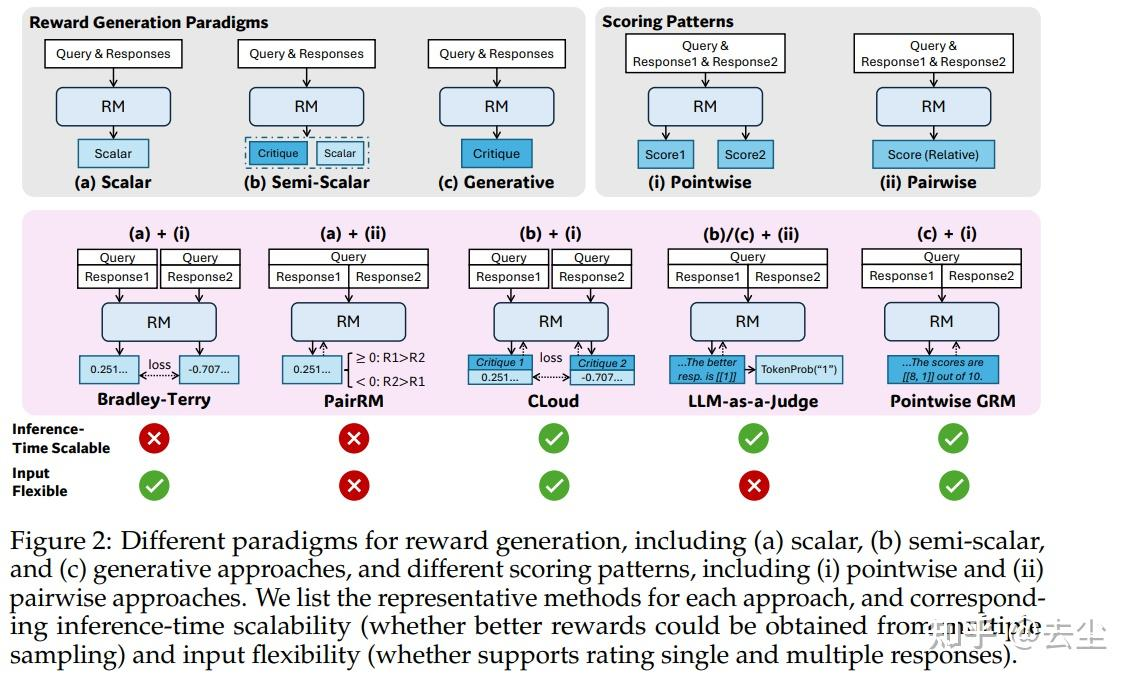

In [31]:
Image(filename='./Image/sft_rl_15.jpg')

但真正把 GenRM 从“逐条打分的小裁判”推向“RL 基建支柱”的，是 2026 年前沿模型中的 Agentic Grader。它有三个质变特征：

① 从“逐条打分”到“组级对比排序”。MiMo-V2.6 的 Groupwise Agentic Grading 把同一 rollout group 内所有轨迹放进同一个 workspace，让 SFT 训练的 agentic grader同时检视成功和失败的轨迹，对比通过测试的候选方案，沿五个维度排序：方案适合度、实现精度、最小性（相对必要改动）、副作用规避、代码风格一致性。这不是逐条打分，而是组内相对排序——天然适合 GRPO 的组相对优势框架。补一句谱系：报告里 Groupwise Agentic Grading 有两条路径——GRS（Groupwise Reward Synthesis，离线合成 solution/behavior 两套 rubric，用于高通过率子集）与GAR（Groupwise Advantage Redistribution，在线五维排序，用于其余任务）；上面描述的 workspace 对比排序是其中的在线 GAR 路径。

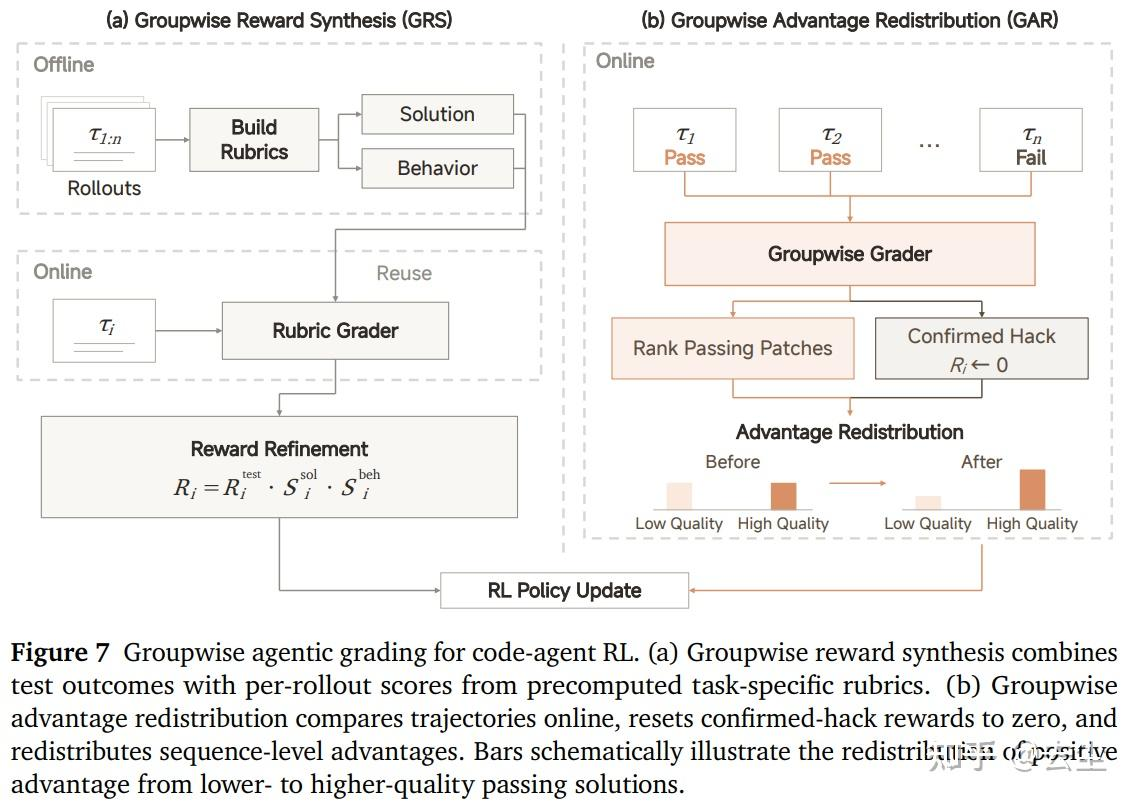

In [32]:
Image(filename='./Image/sft_rl_16.jpg')

② 从“输出标量”到“credit redistribution”。 MiMo-V2.6 的 GAR（Groupwise Advantage Redistribution）不只排序，还改变 advantage 的分配形状：对通过测试的轨迹，按质量因子 
 对低质量通过者降权，再用一个公共缩放因子把“被剥夺的正 advantage 质量”重新分配给高质量通过者，同时保持组内正 advantage 总和不变、失败轨迹的 advantage 不变。对确认 reward hacking 的轨迹，直接把 effective reward 置零后重算组统计量。换句话说，GenRM 的输出不再只是一个 reward 信号，而是直接改变了 RL 的梯度形状。

③ 从“单一裁判”到“混合奖励栈中的固定层”。 GLM-5 的通用 RL 使用 hybrid reward system，把 rule-based reward、ORM 和 GRM 三类信号混合：rule 负责精确可表达的部分，ORM 负责低方差高吞吐的部分，GRM 负责开放域、难以用规则表达的质量判断。三者的组合不是可选项，而是稳定训练的必要条件——单一信号源的弱点（rule 太窄、ORM 易被 hack、GRM 方差大）被另外两类补上。

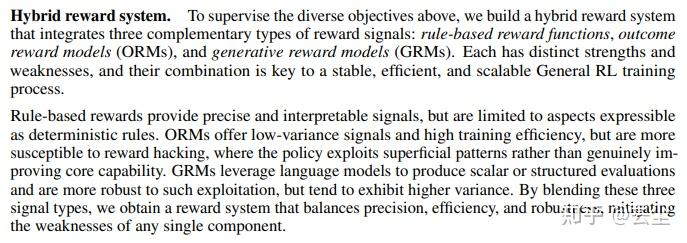

In [33]:
Image(filename='./Image/sft_rl_17.jpg')

开源侧的规格也在质变。NVIDIA 在 2026 年 3 月发布的 Qwen3-Nemotron-235B-A22B-GenRM（Apache 2.0）是一个明确信号：235B 总参 / 22B 激活、128K 上下文，定位就是 reward model 用于 RLHF 训练，不是通用对话模型。

- Infra 表现：它的行为和 Rollout 引擎一模一样，需要逐 Token 的 Decode，因此极度吃显存和算力。但 2026 年的关键变化是：当 grader 占 12.7% 的 RL 总 compute 时，它就不能再和 Rollout 挤在同一张卡上靠 wake_up/sleep 轮转来凑合了。MiMo-V2.6 的做法是把 grader 与 Agent Loop 完全异步：grader 的延迟被隐藏，结果可以滞后返回，group 的 accept/reject 在 metadata 上完成，而不阻塞 Rollout 的连续推进。这个异步化不是“优化”，而是“grader 升级为大组件之后的必然架构选择”——这一点和第 5 章的网关记账、第 7 章的异步运维是同一根链条上的三个断面。

### 4.2.4 类型四：Independent RM Pool（独立奖励池）—— 资源解耦，在 2026 年从“可选”变成“刚需”
当奖励框（不管是 GenRM 还是 Discriminative RM）太大，比如 70B 级别，把它和训练、Rollout 挤在同一张卡上必然 OOM。2026 年的新情况是：235B 级别的专用 GenRM 让“共卡模式”从“勉强能跑”变成了“彻底不成立”。Qwen3-Nemotron-235B-A22B-GenRM 这种规格，不可能和 552B 的 actor、推理引擎共享同一组 GPU。

  - Infra 表现：配置 reward.reward_model.enable_resource_pool=True。它会拥有自己独立的 Ray Actor 和 GPU 池。Rollout 产出的数据通过 HTTP 异步打给它，完全解耦。2026 年的补充是：异步解耦不仅是“省显存”，更是“让 grader 的延迟不进入 Rollout 的关键路径”——grader 可以滞后返回结果，group 的 accept/reject 在 metadata 上完成，Rollout 继续推进。这与 4.2.3 的 Agentic Grader 异步化是同一件事的两个侧面。
  
一句话总结：2026 年的奖励框不再是“一个打分器”，而是“一个需要独立核算算力、需要异步解耦、并且能直接改变 RL 梯度形状的 RL 基建支柱”——Rule-based 提供确定性验证，Discriminative 提供便宜的前向打分，Agentic Grader 提供组级排序与 credit redistribution，Independent Pool 提供资源与延迟的解耦。四类不是并列选项，而是同一条奖励流水线上从“便宜”到“昂贵”、从“标量”到“梯度形状”的连续谱。

## 4.3 轨迹与奖励的碰撞：多轮数据如何喂给 RM？
结合《verl原生多轮工具调用AgentLoop全链路解析》，Rollout 产出的数据是高度非结构化的。当这些数据流经 Reward 框时，必须经历极其痛苦的清洗。

### 4.3.1 掩码（Mask）截断与观测丢弃
看 Rollout 写入 TQ 的 response_mask：1 代表模型生成的思考/工具调用，0 代表环境返回的观测（Observation）。 当 Reward 框（比如 Rule-based）需要拿代码去执行时，它必须只提取 response_mask == 1 的部分，或者通过正则精确切分，否则会把环境的返回值当成模型写的代码去跑，直接崩溃。

### 4.3.2 格式黑洞：双 Tokenizer 适配
这是最容易踩坑的地方。随意举个例子：Actor 可能是用 Qwen 跑的，但 Reward Model 可能是个 Llama。verl 的_preprocess_reward_inputs（reward_loop.py）为此显式持有两个 tokenizer：input_tokenizer（训练侧）与reward_model_tokenizer（config.reward.reward_model.model_path，reward_loop.py）。

从 TQ 里捞出的 response_ids（包含工具交互），是 Qwen Tokenizer 生成的。
_preprocess_reward_inputs 必须先用 Qwen 的 Tokenizer 解码，把长长的 token 列表还原成 Chat template 格式的文本。
再用 Llama 的 Tokenizer 重新编码。
更别提还要处理 Llama 默认加 BOS、以及工具调用格式在重新编码后的偏移。
### 4.3.3 路由分发：data_source 的魔法
一个 Batch 里的数据往往来自不同的数据集（比如一半是数学，一半是代码）。Reward 框是如何分辨的？ 它读取 TQ 里的非张量元数据 data_source，在 compute_score 函数里通过字典去路由：if data_source == 'gsm8k': ... elif data_source == 'mbpp': ...。

## 4.4 资源的博弈：共卡 RM 的“极限显存体操”
这是 reward.reward_model.enable_resource_pool=False（默认）模式下的经典灾难。

如果 Reward 框是模型，它必然要占用 GPU。而在共卡模式下，它只能和训练框、Rollout 框抢显存。在代码 RewardLoopManager.compute_rm_score 里，发生着极其暴力的时序：

In [ ]:
# reward_loop.py:RewardLoopManager.compute_rm_score（节选）
def compute_rm_score(self, data: DataProto) -> DataProto:
    if self.reward_model_manager is not None:
        self.reward_model_manager.wake_up()  # ① 强行唤醒 RM 权重，抢走 Rollout 的显存
    
    # ... 此时 Rollout 引擎被强制挂起，RM 引擎疯狂推理 ...
    
    if self.reward_model_manager is not None:
        self.reward_model_manager.sleep()    # ② 算完立刻休眠，把卡还给 Rollout/训练

读完这段代码，就明白为什么在大规模 Agentic RL 里，必须配独立 Reward 池。 否则，Rollout 生成长尾卡一下，RM 醒不来；RM 推理慢了，训练框也得跟着干等。

## 4.5 形状的膨胀与落库：从标量到 Token 级权重
RM 引擎输出的往往是一个 Scalar（比如 0.8 分）。但 PPO/GRPO 训练需要的是与序列等长的 Token Tensor。

assemble_rm_scores 做了最后一道“形状翻译”：

1. 它创建一个与 responses 等长的全 0 张量。
2. 根据每条轨迹的 response_len，把这个标量硬生生地塞到最后一个有效 Token（EOS）的位置。
3. 为了省显存，它不使用 Padding 后的 Dense Tensor，而是使用 Jagged (Nested) Tensor（如 [1.0, 0.0, 0.0, 0.8]，长度因样本而异）写回 TQ。

## 4.6 环上的七类活状态（呼应 1.2 的“有状态”）
看回 1.2 节的图，为什么系统有七类活状态？因为信息不仅沿着边流动，还沉淀在各处。

In [ ]:
Image(filename='./Image/sft_rl_17.1.png')

结论：RL 循环的本质，就是“在满是地雷的异步状态机里，通过极其严密的版本控制和资源调度，把生成的轨迹变成合法的梯度”。而奖励框（框 C），就是这条链路上最容易掉链子、最需要 Infra 重点保护的核心环节。

# 5. Rollout 子系统：从底层引擎到 Agentic 网关
这一节讲什么：4.1节 的步骤 1
采
样
背后，是整个 RL 系统中状态最复杂、最容易 OOM 的巨兽。在 SFT 时代，推理只是一个简单的 Forward；但在 Agentic RL 里，它是一整条多轮状态机。本节将拆解 Rollout 如何从单纯的“推理调用栈”，演化出复杂的工具状态机，以及为了兼容生产环境的黑盒 Agent 而诞生的网关式记账架构。

(注：关于原生 AgentLoop 和网关适配器的逐行代码级解析，请参阅本系列的深度扩展篇《verl原生多轮工具调用AgentLoop全链路解析》与《MiMo网关式适配器AgentFrameworkRolloutAdapter深度解析》。)

## 5.1 原生链路的骨架：非阻塞派发与 Tag 协议
在 verl 的 V1 架构中，Rollout 的入口是 AgentLoopManagerTQ。它的核心逻辑是“发完不管”。

In [ ]:
# agent_loop_tq.py:AgentLoopManagerTQ.generate_sequences
def generate_sequences(self, prompts: TensorDict) -> None:
    # 把 batch 切块，扔给底层的 Worker，立刻返回

因为它不阻塞等待，Trainer 怎么知道数据准备到哪一步了？答案是 TransferQueue TQ 的两级 Tag 协议：

1. Prompt 级 Tag：running（正在跑） -> finished（跑完了）或 failure（跑挂了）。
2. 轨迹级 Tag：status="success", prompt_len, response_len。

ReplayBuffer（7.2节会讲）就是靠轮询这些 Tag，来决定何时拉起下一个训练步的。

## 5.2 核心机制：ToolAgentLoop 状态机与 Token 记账
这是原生 Agentic RL 的心脏。对于多轮工具调用，verl 没有使用粗暴的 while 循环，而是设计了一个清晰的四态状态机（tool_agent_loop.py）：

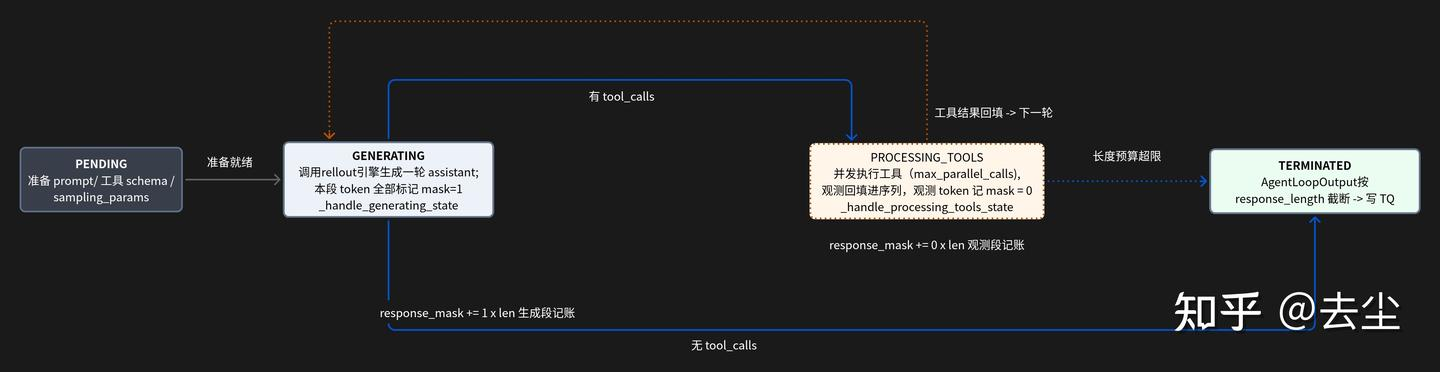

In [34]:
Image(filename='./Image/sft_rl_18.jpg')

### 5.2.1 生成段 vs 观测段的 Mask 魔法
在这个状态机中，最关键的 Infra 动作是维护 response_mask（这是训练框唯一认的账）：

  - 在 GENERATING 状态：模型吐出的所有 Token（包括 \<think> 里的深度思考），response_mask 全部追加 1。
  - 在 PROCESSING_TOOLS 状态：环境/工具返回的观测结果（Observation）拼接进序列时，response_mask 全部追加 0。
Infra 决策：为什么要区分 1 和 0？因为训练（Actor Update）时，只有 mask=1 的 Token 才会被计算梯度。工具返回的代码报错、网页内容，只作为条件上下文，模型不需要（也不应该）去学习生成这些内容。

### 5.2.2 多轮 Token 的连续拼接
原生实现使用了 apply_chat_template 来做增量拼接，并引入了 continuous_token（agent_loop.py:310）来避免多轮场景下整段重排模板导致的重分词漂移。引擎回传的 token ids 直接复用，保证了 prefix cache 的最大命中率。

## 5.3 网关架构：如何让黑盒 Agent 无缝进入 RL？
这才是现代生产级 Agentic RL 最具挑战的部分。

如果我们只能训练自己写的白盒 Agent（ReAct），那就永远是玩具。生产中，我们往往希望用 Claude Code、mini-swe-agent 等黑盒 CLI 工具来跑任务，怎么把它们产生的数据接进训练管线？

MiMo 的答案：AgentFrameworkRolloutAdapter（网关适配器）。

### 5.3.1 核心思路：把“记账权”移交给 HTTP 网关
黑盒 Agent 的最大问题是不可插桩（改不了它的源码）。但它们都有一个共同点：必须发 HTTP 请求才能调模型。

于是，系统在黑盒 Agent 和真实的 vLLM 之间，架设了一个协议兼容的网关（Gateway）。

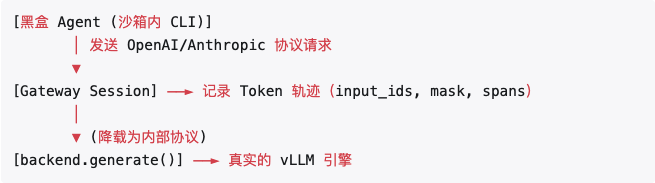

In [35]:
Image(filename='./Image/sft_rl_18.1.png')

黑盒 Agent 以为自己在和 OpenAI 聊天，实际上所有的 Prompt、Response、工具调用，全都被网关截获，并在网关的 GatewaySession 里完成 Token 级记账。

### 5.3.2 request_id = session_id 的精妙耦合
在网关架构中，backend.generate 的 request_id 被直接绑定为 session_id。 这会触发 5.4节 提到的全局负载均衡器（Global LB）的 sticky 路由：一个 session 的所有轮次，都会被粘在同一个 vLLM 副本上。配合网关的增量前缀编码，这个黑盒会话的 Prefix Cache 命中率能达到极高。

## 5.4 殊途同归：白盒与黑盒在 TQ 的出口协议
无论前端是原生的 ToolAgentLoop（白盒），还是 Claude Code（网关黑盒），它们最终写入 TQ 的轨迹数据结构是绝对一致的：

1. 基础张量：prompts, responses（生成+观测交错）, input_ids。
2. 核心掩码：response_mask（模型生成=1，观测=0）。
3. 奖励挂载：rm_scores[-1] = reward_score（把稀疏奖励锚定在最后一个 Token）。
4. 轮次元数据：generation_spans（记录每轮生成的区间），用于后续的高级信号（如 turn_index 和 repetition_mask）。
Infra 视角：无论是哪条链路，只要它们产出的 rm_scores 和 response_mask 形状合法，训练框（Megatron）就完全无感。这正是网关架构的威力——用 HTTP 协议层的中立记录，买来了对无限种 Agent 框架的普适性。

## 5.5 vLLM Server 内部的契约层与显存自救
回到最底层的 vLLM Server（vllm_async_server.py），为了保证上述所有的记账逻辑不被破坏，它内部塞满了 RL 特有的契约：

- 三来源 max_tokens 互斥：上层显式给 / 双引擎参数互认 / 训练长度预算。
- logprobs=0：只要选中 token 的 logprob，计算 ratio 时只需要它。
- abort 兜底：当训练中断或权重更新需要抢显存时，if not final_res.outputs: return TokenOutput(token_ids=[], stop_reason="aborted") 保证不崩。
## 5.6 显存语义：wake_up 与 KV Cache 的作废
当 Rollout 结束，准备把卡交给训练时，最关键的一步在 on_step_end（trainer_colocate_async.py）： rollout.resume(tags=["weights"]) 触发 wake_up，紧接着执行 reset_prefix_cache(reset_connector=True)。

读图要点：wake_up 是权重同步的前置条件。并且，只要新权重进场，旧权重算出的所有 KV 缓存立即变脏。KV 作废由权重版本变更触发，与单次请求结束无关。这是 sticky routing 和 prefix cache 在 RL 中必须配失效逻辑的根本原因。

# 6. 权重同步：跨越边界的“第四态”迁移
这一节讲什么：3.3.4 明确定义了”第四态”——从 param buffer 到”推理引擎内的一份权重”。这条路径不是一次传输，而是穿越多次边界：训练侧内部、语义层（mcore→HF）、物理层（训练集群→推理集群）、推理侧内部。每一次边界都对应一组独立的工程问题。本节用一次完整的权重同步（colocate_async 模式下 on_step_end 触发的那次）作为主线，逐次穿越，最后回到生产视角的失败模式表——告诉读者”遇到哪种症状该往哪里查”。

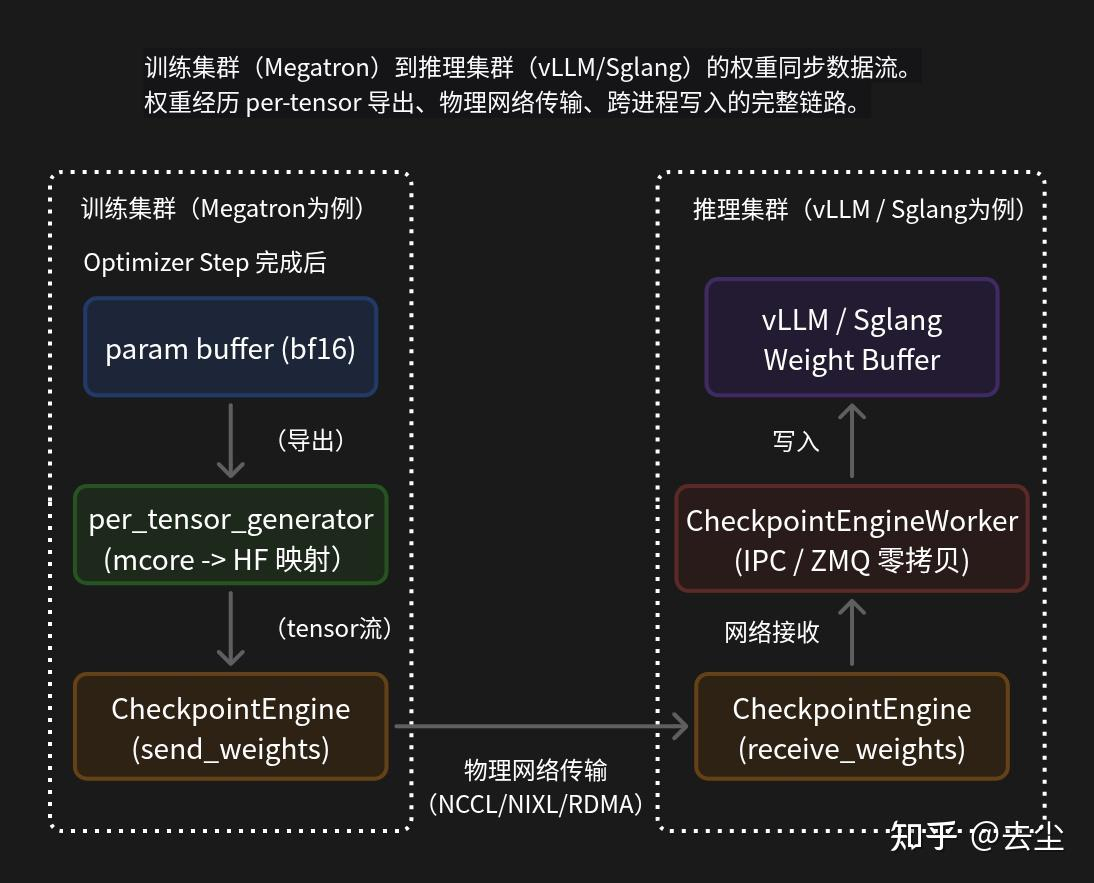

In [36]:
Image(filename='./Image/sft_rl_19.jpg')

# 6.0 一次权重同步的完整时间线
3.3.4 从数据面定义了“第四态”迁移的四次边界：训练侧内部、语义层、物理层、推理侧内部。本节在此基础上增加边界 0（状态切换）和边界 4（一致性恢复），拆成 5 个可观测边界（0–4）：

  - 边界 0：状态切换——同步期间不能有在途请求；
  - 边界 1：mcore→HF——覆盖 3.3.4 的“训练侧内部 + 语义层”，可细分为 1a 训练侧内部重排（Bucket→per-tensor、TP all-gather）与 1b 语义层映射（mcore 命名→HF 命名、QKV 拆分、精度转换）；
  - 边界 2：跨集群传输——物理网络；
  - 边界 3：跨进程 IPC——推理 Worker→vLLM 引擎；
  - 边界 4：一致性恢复——reset prefix cache、恢复 KV、续生成。
其中 1–3 是数据面，0/4 是状态面。本节主线是 colocate_async 模式下 on_step_end 触发的那次同步；sync / separate_async 的触发点与显存动作差异见下表，不重复第 2 章的调度细节。

先看这条时间线的全貌，本节后面所有小节都对应到它的某一段：



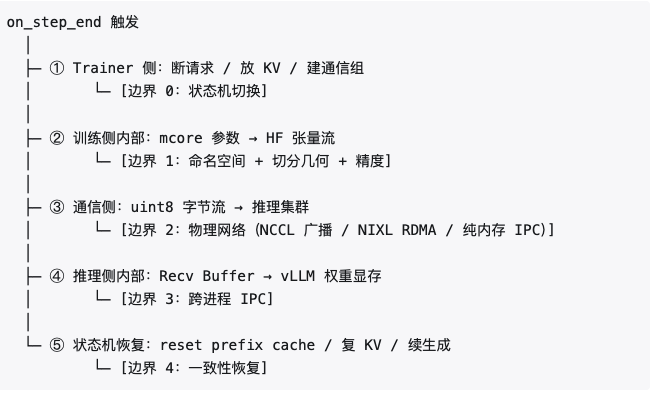

In [37]:
Image(filename='./Image/sft_rl_19.1.png')

读图要点：五次边界严格按“状态切换 → 训练侧内部/语义层 → 训练/推理之间 → 推理侧内部 → 状态恢复”的顺序发生。每一个边界都对应一类独立失败模式——6.6 就是按这五次边界组织的。

## 6.1 边界 0：状态机切换（同步期间不能有在途请求）
为什么会有这条边界：on_step_end 触发时，rollout 引擎可能还在跑几千个 generate() 请求。这些请求的 KV cache 是基于旧权重算的；如果一边同步新权重一边继续生成，新的 KV 会用旧权重写，旧的 KV 会用新权重读——这是物理上的不可恢复错误。

解法只有三步，且顺序不能错：



In [ ]:
# base.py:CheckpointEngineManager.update_weights（节选）
# 1. 中断所有在途请求（保存到 partial rollout 队列）
await self.abort_replicas()
# 2. 释放 KV cache（权重显存保留）
await self.release_kv_cache_replicas()
# 3. ... 执行传输 ...
# 4. 恢复 KV cache
await self.resume_kv_cache_replicas()
# 5. 恢复之前中断的请求（基于新权重继续生成）
await self.resume_generation_replicas()

为什么 colocate_async 的零拷贝窗口用 release_kv_cache 而不是 sleep_replicas：

- sleep_replicas 是整块 sleep/wake，适合 sync 的串行时间分片；但 colocate_async 的权重同步要走 NCCL/IPC 原地写入接收侧权重显存，接收 Buffer 需要权重显存仍是有效地址。
- 因此同步窗口只释放 KV，让出显存给 recv_buf，权重显存原地保留——这是 NCCL/IPC 能“零拷贝写入”的前提。
- 注意：2.2 时间轴里的 on_sample_end abort+sleep 是“让出训练显存”的入口；update_weights 里的 abort_replicas/release_kv_cache_replicas 是权重同步入口的幂等兜底。在 partial rollout 或 separate_async 的备胎路径下，在途请求可能仍在，必须执行；在 sync 下串行无在途，separate_async 的 standalone 常驻不 sleep，二者不能套用这条零拷贝解释。

边界 0 的失败模式：如果忘记 abort_replicas，在途请求的 KV 会由旧权重写、新权重读，轨迹本身不自洽。后果不是简单的“ratio 分母错”——7.1 重算 old_log_prob 只能修正分母口径，救不回轨迹质量；7.4 的 rollout_log_probs / IS/RS 也会与生成时策略错位。定位时先看 rollout_corr/kl、rollout_corr/chi2_seq，再回查 on_sample_end 与 update_weights 的 abort 顺序。

## 6.2 边界 1：从 mcore 参数到 HF 张量流
为什么会有这条边界：训练侧的 param buffer 是mcore 物理布局（按 bucket 把不同层混在一起，TP 切分），而推理引擎需要HF 逻辑布局（按 tensor 独立命名，完整形状）。这不是”改个名字”，而是物理上要重排数据。 子问题 0：从 optimizer Bucket 还原 per-tensor。 3.3.2 的 DistributedOptimizer 按连续区间切分 fp32 主参数——张量本身不跨 Bucket（Bucket 以整参数为界），被切进张量中间的是每个 rank 持有的 shard 区间边界。导出前必须把分片还原成 per-tensor：这一步由训练引擎的导出器完成（get_per_tensor_param → per_tensor_generator，verl/utils/megatron_utils.py），Tensor 级的 TensorMeta（name/shape/dtype/chunk_offset/chunk_size/offset，base.py）是传输层分块元数据，属于 6.3.2，不负责这层还原。导出路径按“全量 / 分片”分两族，且这是引擎的导出能力，与优化器底座（DDP vs Megatron-FSDP）正交：

  - 全量导出：get_per_tensor_param（transformer_impl.py）——内部做 TP/EP all-gather、tp_concat_fn 拆分、bridge 转换；
  - 分片 / 增量导出：get_per_tensor_param_shard（每 rank 只出本地 shard）与 get_per_tensor_param_delta_shard（对 pinned 快照 diff 后只出变化量），专为 6.3.1 的 delta_sharded 后端服务——注意该后端目前仅支持 sglang rollout（base.py：稀疏 apply 经 sglang 的 custom-weight-loader hook 下发，其他后端是规划中的 follow-up）。 三个子问题必须同时解决：

### 6.2.1 子问题 1：命名空间映射
mcore 的命名按模块路径组织，HF 的命名按 model.layers.{i}.self_attn.* 组织，两者不是简单替换。典型映射如下：

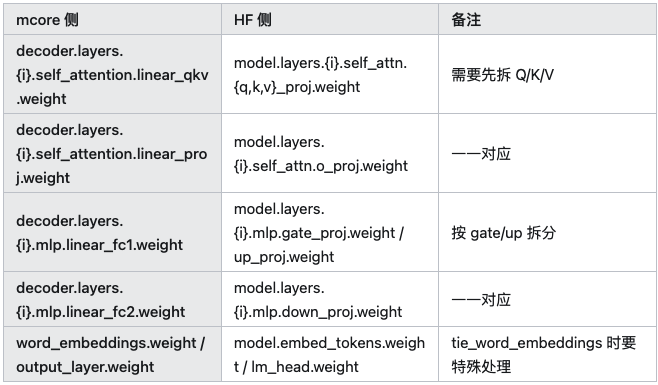

In [38]:
Image(filename='./Image/sft_rl_19.2.png')

解法：bridge 的“真值映射表”——weight_converter.convert_param 拿着映射表逐条翻译，把 mcore 名字翻译成 HF 名字，同时决定这个张量属于 HF 的哪一部分。真值表由 bridge 按 HF config 生成，convert_param 逐条消费；映射表错一条，就是 6.6 里“loss 不炸但质量缓慢劣化”的典型来源。

### 6.2.2 子问题 2：切分几何重组
这是最致命的一层——训练侧把 linear_qkv 的 Q/K/V 拼在一起；推理侧要求 Q/K/V 独立张量，且每个张量的 TP 切分方式与训练侧不同。

In [ ]:
# megatron_utils.py:default_tp_concat_fn

# 拆 Q/K/V 的关键逻辑（节选，逐字）
if layer_name_mapping.get("qkv_layer_name") in name and "layer_norm" not in name:
    num_q_per_kv = num_attention_heads // num_key_value_heads
    kv_size_per_tp = infer_params[0].shape[0] // (num_q_per_kv + 2)
    split_size = [kv_size_per_tp * num_q_per_kv, kv_size_per_tp, kv_size_per_tp]

    for infer_param in infer_params:
        for chunk in infer_param.chunk(num_query_groups_per_partition):
            q, k, v = chunk.split(split_size)
            q_lst.append(q); k_lst.append(k); v_lst.append(v)

    q = torch.cat(q_lst, dim=0)
    k = torch.cat(k_lst, dim=0)
    v = torch.cat(v_lst, dim=0)
    infer_params = [q, k, v]

这段代码解决的是一件事：QKV 拆分（按num_q_per_kv + 2的比例把linear_qkv拆成独立的 Q、K、V，按 query group 重排后拼接）。

子问题 3：精度转换——训练侧是 bf16 param + fp32 main，推理侧可能是 FP8。但要注意：默认同步链上传的是 bf16 named tensors（vllm_rollout.py 显式断言只接受 named tensors），bf16→FP8 的量化不在默认链上——它走独立分支：ModelOpt/QAT 的量化导出（_qat_enabled → export_qat_weights，transformer_impl.py），或推理引擎加载时的量化配置。这是 7.1 里 FP8 logprobs 不能直接用的物理根源——因为从这一步开始，推理侧的权重就是“损失过版本”。
边界 1 的失败模式：如果映射表错一条，或者 Q/K/V 拆分比例错一个 head，loss 不炸但质量缓慢劣化——这是最难查的失败模式（6.6 详细）。

## 6.3 边界 2：从训练集群到推理集群
为什么会有这条边界：训练侧和推理侧在物理上是两组 GPU，中间隔着网络。这一层要解决的是“传什么、用什么传、怎么传得快”——三个正交的子问题。

### 6.3.1 子问题 1：传多少（三种同步模式）
verl 的“传多少”由 checkpoint engine 后端决定，注册表里分三族：

- naive（同进程，传引用）：ColocatedCheckpointEngine 的 send_weights 只是存下生成器对象，receive_weights 原样 yield from（base.py）——训练与推理同进程时连传输通道都不需要。
- 全量分桶（nccl / nixl / mooncake / kimi_ckpt_engine）：每次同步从 per-tensor 流出发，按 bucket 打包全量传输——这是 6.3.2 的主线。
- delta_sharded（增量稀疏）：本小节主角。每个 rank 维护自己 shard 的 pinned-CPU snapshot，本地 diff 出变化的稀疏载荷，只推变化的 (position, value) 对；推理端解码后原位 masked-apply。首同步（seed）仍走全量，但流式分桶，峰值显存 ~2 桶而非整个模型。已核实测锚点：7B 模型稳态每次 ~2.4s、全量 seed ~83s（delta_checkpoint_engine.py）；接收端无全量镜像、峰值约“1 桶 + 1”；稀疏载荷以 64M 元素为界、瞬态约 512 MiB。 一个值得记住的工程坑：_GatherQueue 的 flush 触发必须是 COUNT-ONLY——按字节触发会让各 rank 的集合通信序列错位，NCCL 直接死锁（delta_checkpoint_engine.py 注释逐字：”a per-rank byte trigger desyncs the gathers and deadlocks NCCL”）。因为不同 rank 的参数量不同，“满 64M 元素（瞬态 ~512 MiB）就发”在 rank 0 和 rank 1 触发的时机不一样，集合通信序列错位就死锁；必须按“凑够 N 个参数条目”这种所有 rank 都一致的信号触发。

### 6.3.2 子问题 2：怎么传（三种物理后端）
为什么必须用“桶（Bucket）”打包（base.py:split_weight_chunks）：

  - 如果每个张量都发一次网络包，通信延迟会彻底摧毁吞吐。
  - 解法：把所有张量打平（view(-1).view(torch.uint8)），按 bucket_size 切块，塞进连续 Buffer（send_buf），一次网络包发一整桶。
  - 接收端用 merge_weight_chunks 按 metadata 里的 shape / dtype / offset 切蛋糕式还原。 物理后端注册表（CheckpointEngineRegistry，实际 7 个注册名）：

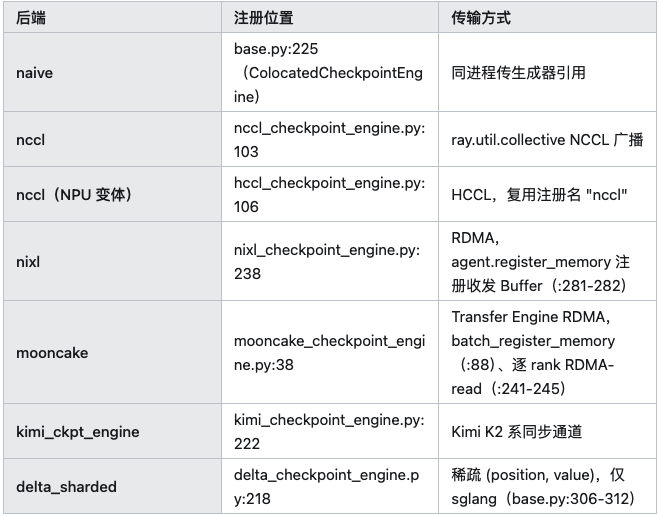

In [39]:
Image(filename='./Image/sft_rl_19.3.png')

注意：这里的“通信 bucket”是 split_weight_chunks 的 send_buf 打包单位，不是 3.3.2 的 optimizer bucket；两者尺寸和边界无关。边界 2 的“零拷贝”指接收侧不额外拷贝到 CPU；边界 3 的“零拷贝”指跨进程不 memcpy。
NCCL 后端的“双缓冲”细节（nccl_checkpoint_engine.py:send_weights）：

In [ ]:
# 双缓冲：send_buf 正在被 NCCL 广播时，CPU 已经在往 recv_buf 填下一块数据
if offset + tensor_meta.chunk_size > self.bucket_size:
    broadcast_op = BroadcastOperation(rank=0, bucket=send_buf, ...)
    send_buf, recv_buf = recv_buf, send_buf  # 交换
    await broadcast_op.wait_for_complete()
send_buf[offset : offset + tensor_meta.chunk_size] = cp.asarray(chunk)

为什么是“2 * bucket_size”的显存开销：因为当一个桶正在发送时，另一个桶已经在填充下一批数据。这是用显存换吞吐的经典 trade-off——在长序列 RL 下 bucket_size 会显著变大，容易 OOM。 元数据与数据面的解耦：由于 NCCL 只能传递连续字节流，verl 使用 ZeroMQ 作为控制面（nccl_checkpoint_engine.py 中的 self.socket，PUB/SUB，:174-191）。在每次 NCCL 广播前，发送端先通过 ZMQ 把 TensorMeta（包含 name、shape、offset）发给接收端。接收端在收到 NCCL 字节流后，依靠 ZMQ 传来的 Meta 信息，用 merge_weight_chunks 把 uint8 再次切回原本的模型权重。 与此相对，NIXL/Mooncake 等 P2P 引擎则更进一步，它们绕过 CPU，通过 RDMA 直接读写对端显存。其底层需要预先通过 Memory Registration 将显存地址注册给网卡，控制面则负责交换 Agent Metadata 和显存句柄。 边界 2 的失败模式：

  - NCCL 死锁（COUNT-ONLY 触发）；
  - 数据损坏（delta 载荷自带 checksum，delta_sync/encode.py；接收侧由 sglang 的 delta_loader 校验后 apply）；
  - 端口冲突（多 Job 共享节点时 ZMQ 路径冲突，见 vllm_async_server.py 里的 VERL_RAY_JOB_ID 隔离）。
  
## 6.4 边界 3：从推理 Worker 到 vLLM 引擎（CUDA IPC）
为什么会有这条边界：权重通过 NCCL 到了推理侧 CheckpointEngineWorker 的显存——但 vLLM 引擎在另一个进程里。跨进程共享显存在 CUDA 里是个专门机制：CUDA IPC。

补充说明：如果使用的是 backend="naive"（同进程模式），CheckpointEngine 只是把生成器对象直接传引用，连 CUDA IPC 都不需要。但绝大多数生产环境使用的是 colocate_async（同卡跨进程），此时训练进程和 vLLM Worker 是隔离的，必须走 CUDA IPC。这才是 verl 设计中真正要解决的痛点。

解法的核心（vllm_rollout.py:update_weights）：

In [ ]:
# 1. 触发 vLLM 侧的接收方法（异步）
future = await self._execute_method("update_weights_from_ipc", non_block=True, ...)

# 2. ZMQ 发送显存句柄（不是数据！）
sender = BucketedWeightSender(zmq_handle=self.zmq_handle, ...)
await sender.async_send_weights(weights)

关键在“零拷贝”：

- BucketedWeightSender 通过 torch.multiprocessing.reductions.reduce_tensor 生成显存句柄（一段描述符，几十字节）；
- ZMQ 把这个句柄发到 vLLM 的 Worker 进程；
- vLLM 用 rebuild_ipc 通过句柄直接映射这段显存——全程不 memcpy。
- 兜底：IPC 不被环境支持时回退共享内存（update_weights 的 docstring 即 “via CUDA IPC (fallback to shared memory if IPC not supported)“，vllm_rollout.py；use_shm 参数）。 为什么要零拷贝：一个 30B 模型一次权重同步是 60GB。如果走 memcpy，通信时间会从毫秒级涨到秒级。这是为什么 verl 不用“torch.save 到磁盘再加载”这类笨办法的根本原因。 边界 3 的失败模式：IPC 句柄泄漏（旧句柄不释放导致显存泄漏）；端口冲突（多 Job 共享节点时 ZMQ socket 冲突，句柄形如 ipc:///tmp/rl-colocate-zmq-.sock，bucketed_weight_transfer.py）。

## 6.5 边界 4：状态机恢复（新权重到场之后）
这一步最容易被忽略，但踩坑最多——因为它是"权重同步看起来完成了，但系统状态没有同步"。
传输完成后要做的恢复分散在两层，用已核实的调用链表示：

In [ ]:
# —— rollout 侧（vllm_async_server.py:770-787）——
async def wake_up(self, tags: list[str] | None = None):
    # HYBRID 模式下 engine.wake_up() 经 DP 协调器广播到所有 DP shard 的 EngineCore
    await self.engine.wake_up(tags=tags or self._get_wake_up_tags())
    await self.engine.reset_prefix_cache(reset_connector=True)   # :779/:787

# —— manager 层收尾（verl/checkpoint_engine/base.py:532-536）——
await self.resume_kv_cache_replicas()      # 恢复边界 0 释放的 KV 显存
await self.resume_generation_replicas()    # 恢复中断请求（trainer_colocate_async.py:51-53
                                           #  在 update_weights 返回后显式再调一次）

reset_prefix_cache(reset_connector=True) 的两个细节：

- 为什么是 reset_prefix_cache 而不是“等它自然过期”：权重一变，所有 KV 立即变脏——旧权重算出的 KV 和基于新权重的 logprobs 会在数学上严重错配。
- reset_connector=True 是什么：同时丢弃外部 KV 存储（如 MooncakeStoreConnector）里的条目——那些条目的权重版本更旧，比 prefix cache 更该清（源码注释逐字：”reset_connector=True drops any attached external KV store (e.g. MooncakeStoreConnector) whose entries were computed against the previous model weights”，vllm_async_server.py:783-786/:804-807）。 版本号协议——当前实现与设计要求的区分：verl 现在每次同步携带 global_steps 作为版本标识（update_weights(global_steps=…)，base.py；各后端 send_weights 也接收 global_steps 参数）。而“KV cache、prefix cache、外部 connector、路由回放缓存全链路挂统一版本号”是设计要求，verl 尚未完整实现——已有的两块拼图是 reset_prefix_cache(reset_connector=True)（清 KV + connector 两路）与 3.1.5 节的 enable_routing_replay（MoE 路由一致性靠路由回放保证）。 边界 4 的失败模式：如果忘了 reset_prefix_cache，会出现同一个 prompt 在新旧权重上得到两种不同的生成结果——这是“权重变了但 KV 没变”的典型症状，极难查。

## 6.6 生产视角：失败模式速查表
把上面五次边界的失败模式汇总，方便生产时按”症状 → 边界”定位：

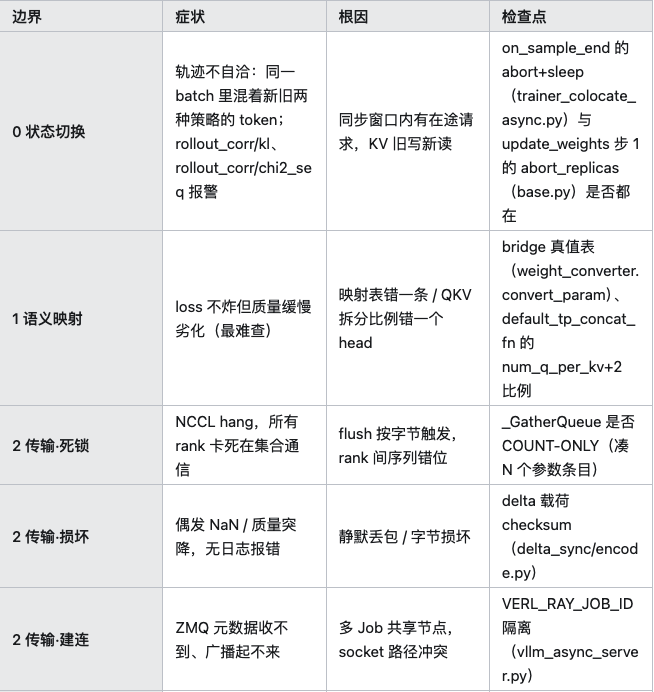

In [40]:
Image(filename='./Image/sft_rl_19.4.png')

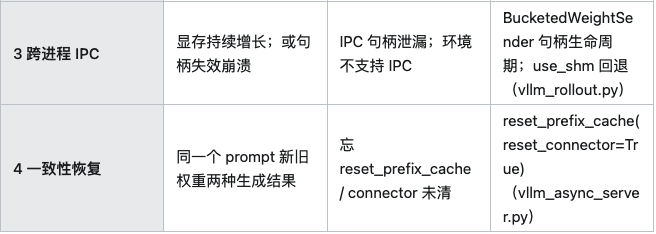

In [41]:
Image(filename='./Image/sft_rl_19.5.png')

读表要点：五次边界（0–4）中，0/4 是状态一致性，1–3 是数据一致性；3.3.4 的三层不一致落在边界 1，5.6 的 KV 失效语义落在边界 4。所有 RL Infra 的权重同步问题，都能定位到这五次边界之一——这是 6 相对 3 和 5 最大的价值：把“看起来玄学”的问题变成“按边界分类”的工程定位。

# 7. 异步训练的运维指南：staleness 与三层防线
这一节讲什么：2.4 已经点明”异步模式的代价是 staleness”——separate_async 下 rollout 用的是若干步之前的权重。这是结构性属性，不是 bug。本节是那份代价的运维手册：三层防线分别怎么在代码里落地、IS 和 RS 各自改什么、以及 staleness 爆表时该怎么查。

## 7.0 为什么会有 staleness
rollout 生成轨迹时用的是
，等这批轨迹走完训练流程，训练侧可能已经更新到
 。这个版本差就是 staleness。

SFT 为什么没有：数据与权重解耦，”这份数据是谁生成的”不构成问题。RL 的轨迹是策略自产，生成时刻的策略和训练时刻的策略必须能对上——否则 ratio 的分子分母不匹配，梯度方向就错了。

为什么不能全都用 sync 模式：sync 下 rollout 引擎在训练时段空转 50%+，硬件利用率不到一半。separate_async 用版本漂移换吞吐，但必须付出代价——这个代价就是需要三层防线，逐层修掉 staleness 带来的偏差。

需要区分两个数：

- 理论上界 = parameter_sync_step（separate 默认 4）。这是”权重同步周期”直接决定的结构性上界：一批轨迹从出生到被消费，最多跨越 parameter_sync_step 个版本。2.4 说的”≤ parameter_sync_step“、6.0 表里 separate_async 那一行，指的都是这个数。
- 运维驱逐线 = max_off_policy_threshold（默认 8）。它是 ReplayBufferAsync 的保守驱逐阈值，允许大于理论上界——因为长尾轨迹可能跨多个同步周期才完成，驱逐线留了余量；超过 8 才判定”这条轨迹不值得再等”。
7.2 的 drop/wait 闸门用的是后者；7.0 开头的”4 步之前”说的是前者。两者不是同一个数，读者不要混。

三层防线的分工：

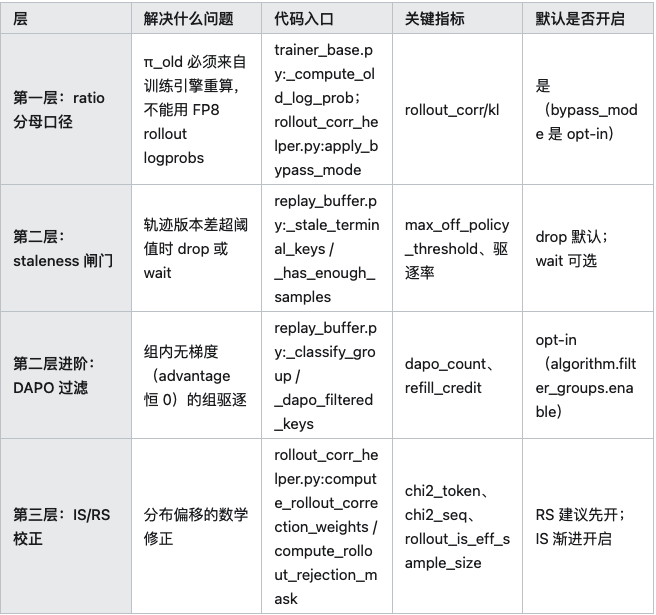

In [42]:
Image(filename='./Image/sft_rl_19.6.png')